# Ghana Food Security Risk Simulator (v2) — Week 1 Data Ingestion Pipeline

This JupyterLab notebook automates the initial data gathering and preprocessing steps for predicting subnational food security risk across Ghana's 16 administrative regions:

1. **Subnational CHIRPS Rainfall (HDX / WFP):** Downloads and caches 10-day (dekadal) rainfall and anomaly series, aggregating them into annual and growing-season (April–October) drought indicators by region.
2. **National Macro-Agricultural Covariates (World Bank API):** Fetches annual fertilizer consumption, national cereal yield benchmarks, population growth, undernourishment prevalence, and CPI inflation via `wbdata`.
3. **MoFA SRID Regional Staple Production Template:** Initializes a structured `Region × Year` CSV template for Ghana Ministry of Food and Agriculture (MoFA) staple crop yields (maize, rice, cassava, yam, millet, sorghum).

## 1. Environment Setup & Dependencies
Uncomment and run the `%pip install` line below if any required packages are missing from your JupyterLab environment.

In [4]:
# Uncomment the line below if you need to install dependencies in your kernel
%pip install -q pandas numpy requests wbdata pyarrow

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import requests
import wbdata

# ---------------------------------------------------------------------------
# Directory & Constant Configuration
# ---------------------------------------------------------------------------
# Create local storage folders for raw downloads and cleaned Parquet outputs
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Direct download URL for WFP/HDX Ghana subnational rainfall estimates (CHIRPS)
HDX_RAINFALL_URL = (
    "https://data.humdata.org/dataset/187fc57e-07af-43d9-b412-6aaba91a3209/"
    "resource/23e0d7d8-2f33-4844-aaff-d056d26b385a/download/gha-rainfall-subnat-full.csv"
)

# Canonical 16 administrative regions of Ghana (aligned with post-2019 boundaries)
GHANA_REGIONS_16 = [
    "Ahafo", "Ashanti", "Bono", "Bono East", "Central", "Eastern",
    "Greater Accra", "North East", "Northern", "Oti", "Savannah",
    "Upper East", "Upper West", "Volta", "Western", "Western North"
]

print("Directories configured:", RAW_DIR.resolve(), "and", PROCESSED_DIR.resolve())

Directories configured: C:\Users\user\data-science-portfolio\ghana-food-security-analysis\v2\data\raw and C:\Users\user\data-science-portfolio\ghana-food-security-analysis\v2\data\processed


## 2. Subnational CHIRPS Rainfall Ingestion (HDX / WFP)
Downloads the dekadal subnational rainfall file (~43 MB), caches it locally in `data/raw/`, strips any HXL metadata header row, and aggregates rainfall totals and drought anomalies to `Region × Year`.

In [12]:
def fetch_hdx_rainfall(force_download: bool = False) -> pd.DataFrame:
    """
    Downloads and aggregates HDX/WFP subnational CHIRPS rainfall to Region x Year.

    Parameters
    ----------
    force_download : bool, default False
        If True, re-downloads the CSV from HDX even if a cached copy exists locally.

    Returns
    -------
    pd.DataFrame
        Aggregated annual and growing-season rainfall features keyed by `region_key` and `year`.
    """
    raw_csv = RAW_DIR / "gha-rainfall-subnat-full.csv"

    # Cache the raw CSV locally so subsequent notebook runs execute in seconds
    if not raw_csv.exists() or force_download:
        print(f"Downloading HDX subnational rainfall data to {raw_csv}...")
        resp = requests.get(HDX_RAINFALL_URL, timeout=60)
        resp.raise_for_status()
        raw_csv.write_bytes(resp.content)
        print("Download complete.")
    else:
        print(f"Loading cached HDX rainfall from {raw_csv}...")

    # HDX datasets frequently include an HXL metadata tag row on line 2 (starting with '#').
    # Inspect the first two lines so we skip the HXL tag row without dropping real data.
    with open(raw_csv, "r", encoding="utf-8") as f:
        _ = f.readline()
        second_line = f.readline()
    skiprows = [1] if second_line.startswith("#") else None

    df = pd.read_csv(raw_csv, skiprows=skiprows, low_memory=False)
    print("Detected CSV columns:", df.columns.tolist())

    # Parse observation dates and extract calendar year and month for seasonal filtering
    df["date"] = pd.to_datetime(df["date"])
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    # WFP HDX rainfall files include `adm_level`, `adm_id`, and `PCODE`.
    # Filter to Admin-1 (regions) when `adm_level` is present so district rows aren't double-counted.
    if "adm_level" in df.columns:
        df = df[df["adm_level"] == 1].copy()

    # Resolve the administrative identifier column flexibly (case-insensitive)
    col_lookup = {c.lower(): c for c in df.columns}
    if "adm1_name" in col_lookup:
        group_col = col_lookup["adm1_name"]
    elif "pcode" in col_lookup:
        pcode_col = col_lookup["pcode"]
        df["adm1_pcode"] = df[pcode_col].astype(str).str[:4]
        group_col = "adm1_pcode"
    elif "adm1_pcode" in col_lookup:
        group_col = col_lookup["adm1_pcode"]
    elif "adm2_pcode" in col_lookup:
        pcode_col = col_lookup["adm2_pcode"]
        df["adm1_pcode"] = df[pcode_col].astype(str).str[:4]
        group_col = "adm1_pcode"
    else:
        raise KeyError(f"Could not find an administrative column in: {df.columns.tolist()}")

    # Filter to 2000–2025 to align with modern MoFA agricultural reports and World Bank series
    df = df[(df["year"] >= 2000) & (df["year"] <= 2025)].copy()

    # Define Ghana's core agricultural rainy window (April–October), which spans both
    # the southern bimodal major/minor seasons and the northern unimodal rainy season.
    growing_season = df[df["month"].between(4, 10)]

    # Aggregate full-year rainfall totals and drought-stress indicators per region:
    # - rfh: 10-day (dekadal) rainfall total in millimeters
    # - rfq: 10-day rainfall anomaly (% of long-term average; <100% indicates drier than normal)
    # - r3q: 3-month rolling rainfall anomaly (% of long-term average)
    annual_rain = (
        df.groupby([group_col, "year"], as_index=False)
        .agg(
            annual_rainfall_mm=("rfh", "sum"),
            mean_10d_anomaly_pct=("rfq", "mean"),
            min_3m_anomaly_pct=("r3q", "min"),  # Captures sharpest 3-month drought shock
            dry_dekads_count=("rfq", lambda s: (s < 75.0).sum()),  # Severe dry 10-day periods
        )
    )

    # Aggregate rainfall specifically during the April–October crop growing window
    season_rain = (
        growing_season.groupby([group_col, "year"], as_index=False)
        .agg(
            growing_season_rain_mm=("rfh", "sum"),
            growing_season_anomaly_pct=("rfq", "mean"),
        )
    )

    # Merge annual and growing-season metrics into a single Region x Year panel
    rain_panel = pd.merge(annual_rain, season_rain, on=[group_col, "year"], how="left")
    rain_panel.rename(columns={group_col: "region_key"}, inplace=True)
    return rain_panel

# Run rainfall ingestion and display preview
rain_df = fetch_hdx_rainfall(force_download=False)
print(f"Rainfall panel shape: {rain_df.shape} | Years: {rain_df['year'].min()}–{rain_df['year'].max()}")
print("Unique region keys:", rain_df["region_key"].unique().tolist())
display(rain_df.head())

Loading cached HDX rainfall from data\raw\gha-rainfall-subnat-full.csv...
Detected CSV columns: ['date', 'adm_level', 'adm_id', 'PCODE', 'n_pixels', 'rfh', 'rfh_avg', 'r1h', 'r1h_avg', 'r3h', 'r3h_avg', 'rfq', 'r1q', 'r3q', 'version']
Rainfall panel shape: (260, 8) | Years: 2000–2025
Unique region keys: ['GH02', 'GH04', 'GH05', 'GH06', 'GH07', 'GH11', 'GH12', 'GH13', 'GH14', 'GH15']


,region_key,year,annual_rainfall_mm,mean_10d_anomaly_pct,min_3m_anomaly_pct,dry_dekads_count,growing_season_rain_mm,growing_season_anomaly_pct
0,GH02,2000,1182.239343,90.691870,47.489014,14,997.998747,97.690898
1,GH02,2001,1153.483723,84.712848,46.234356,15,938.002518,86.484655
2,GH02,2002,1466.008769,108.172636,67.180780,12,1237.431076,118.976815
3,GH02,2003,1376.417286,104.278264,72.321660,10,1074.273177,97.214058
4,GH02,2004,1310.719296,102.411366,65.968440,13,1026.210523,95.164777


## 3. World Bank Macro & Agricultural Input Covariates
Pulls annual national indicators for Ghana (`GHA`) using `wbdata` to serve as baseline macro features across regions.

In [18]:
def fetch_worldbank_macro() -> pd.DataFrame:
    """
    Pulls Ghana national macro-agricultural covariates via `wbdata`.

    Returns
    -------
    pd.DataFrame
        Annual macro features for Ghana (2000–2025) to join onto regional rows.
    """
    print("Fetching World Bank macro indicators for Ghana (GHA)...")

    # Map World Bank indicator codes to readable column names
    indicators = {
        "AG.CON.FERT.ZS": "fertilizer_kg_per_ha",        # Fertilizer consumption (kg/ha arable land)
        "AG.YLD.CREL.KG": "national_cereal_yield_kg_ha",  # National cereal yield benchmark (kg/ha)
        "SP.POP.GROW": "pop_growth_pct",                  # Annual population growth rate (%)
        "SP.POP.TOTL": "national_population",             # Total national population
        "SN.ITK.DEFC.ZS": "undernourishment_pct",         # Prevalence of undernourishment (% of pop)
        "FP.CPI.TOTL.ZG": "inflation_cpi_pct",            # Consumer price inflation (annual %)
    }

    df_wb = wbdata.get_dataframe(indicators, country="GHA").reset_index()

    # Convert date string to integer year, filter to 2000–2025, and sort chronologically
    df_wb["year"] = pd.to_datetime(df_wb["date"]).dt.year
    df_wb = df_wb[(df_wb["year"] >= 2000) & (df_wb["year"] <= 2025)].sort_values("year")
    df_wb.drop(columns=["date"], inplace=True)

    # Forward-fill occasional trailing reporting lags in World Bank indicators (e.g., 2024–2025)
    df_wb = df_wb.ffill()
    return df_wb

# Run World Bank ingestion and display preview
wb_df = fetch_worldbank_macro()
print(f"World Bank macro shape: {wb_df.shape}")
display(wb_df.tail(10))

Fetching World Bank macro indicators for Ghana (GHA)...
World Bank macro shape: (26, 7)


,fertilizer_kg_per_ha,national_cereal_yield_kg_ha,pop_growth_pct,national_population,undernourishment_pct,inflation_cpi_pct,year
9,22.294199,1842.4,2.276212,29356742.0,9.5,17.454635,2016
8,38.246446,1949.1,2.195358,30008354.0,8.8,12.371922,2017
7,27.550240,2172.6,2.075171,30637585.0,7.5,7.808765,2018
6,40.136089,2346.2,2.007805,31258945.0,6.6,7.143640,2019
5,50.111892,2410.8,1.991820,31887809.0,5.7,9.887290,2020
4,37.363426,2360.5,1.959046,32518665.0,5.6,9.971089,2021
3,36.115416,2410.4,1.920290,33149152.0,5.9,31.255895,2022
2,22.803032,2562.3,1.908603,33787914.0,6.5,38.106966,2023
1,43.313022,2632.2,1.875000,34427414.0,6.4,22.848328,2024
0,43.313022,2632.2,1.832955,35064272.0,6.4,14.204676,2025


## 4. Initialize MoFA Regional Staple Production Template & Save Parquet Outputs
Creates the `Region × Year` template CSV for MoFA SRID regional staple production figures (2015–2024) and exports the cleaned rainfall and World Bank datasets to Parquet.

In [21]:
def init_mofa_crop_template() -> Path:
    """
    Creates a structured Region x Year CSV template for Ghana MoFA SRID
    staple production figures (to be populated via `pdfplumber` or manual entry).

    Returns
    -------
    Path
        File path to the generated template CSV.
    """
    template_path = RAW_DIR / "mofa_regional_staples_template.csv"

    # Only generate the template if it does not already exist so edits aren't overwritten
    if not template_path.exists():
        rows = []
        for year in range(2015, 2025):
            for region in GHANA_REGIONS_16:
                rows.append({
                    "region": region,
                    "year": year,
                    "regional_pop": np.nan,           # Regional population headcount
                    "maize_mt": np.nan,               # Production in Metric Tons (MT)
                    "rice_mt": np.nan,                # Paddy/milled rice production (MT)
                    "cassava_mt": np.nan,             # Cassava production (MT)
                    "yam_mt": np.nan,                 # Yam production (MT)
                    "millet_mt": np.nan,              # Millet production (MT)
                    "sorghum_mt": np.nan,             # Sorghum production (MT)
                    "total_cropped_area_ha": np.nan,  # Total cultivated staple area (Hectares)
                })
        pd.DataFrame(rows).to_csv(template_path, index=False)
        print(f"Created MoFA regional crop entry template at {template_path}")
    else:
        print(f"Template already exists at {template_path}")
    return template_path

# Initialize template and export processed Parquet files
template_file = init_mofa_crop_template()
rain_out = PROCESSED_DIR / "ghana_subnat_rainfall.parquet"
wb_out = PROCESSED_DIR / "ghana_wb_macro.parquet"

rain_df.to_parquet(rain_out, index=False)
wb_df.to_parquet(wb_out, index=False)

print("\n--- Pipeline Export Complete ---")
print(f"Saved: {rain_out}")
print(f"Saved: {wb_out}")
print(f"Template ready: {template_file}")

Template already exists at data\raw\mofa_regional_staples_template.csv

--- Pipeline Export Complete ---
Saved: data\processed\ghana_subnat_rainfall.parquet
Saved: data\processed\ghana_wb_macro.parquet
Template ready: data\raw\mofa_regional_staples_template.csv


In [23]:
"""
P-Code to Region Name Mapping & Validation
==========================================
Maps OCHA/HDX Admin-1 P-codes (GH01–GH16) in the aggregated rainfall dataset
to Ghana's canonical 16 administrative region names so it can be merged
cleanly with the MoFA regional crop production table.
"""

# Standard OCHA/HDX COD-AB Admin-1 P-code lookup dictionary for Ghana's 16 Regions.
# Keys correspond to the 4-character Admin-1 P-codes (`GH01`–`GH16`) found in the
# HDX subnational rainfall dataset, and values match the region names in the MoFA template.
GHANA_PCODE_TO_REGION = {
    "GH01": "Ahafo",
    "GH02": "Ashanti",
    "GH03": "Bono",
    "GH04": "Bono East",
    "GH05": "Central",
    "GH06": "Eastern",
    "GH07": "Greater Accra",
    "GH08": "North East",
    "GH09": "Northern",
    "GH10": "Oti",
    "GH11": "Savannah",
    "GH12": "Upper East",
    "GH13": "Upper West",
    "GH14": "Volta",
    "GH15": "Western",
    "GH16": "Western North",
}

# Load the intermediate Region x Year rainfall Parquet dataset generated in Section 2
rain_df = pd.read_parquet(PROCESSED_DIR / "ghana_subnat_rainfall.parquet")

# Translate each `region_key` P-code (e.g., 'GH02') into its readable `region` name ('Ashanti')
rain_df["region"] = rain_df["region_key"].map(GHANA_PCODE_TO_REGION)

# Data quality check: identify any P-codes that failed to map (resulting in NaN)
# and confirm that all 16 administrative regions are accounted for.
unmapped = rain_df[rain_df["region"].isna()]["region_key"].unique().tolist()
print("Unmapped keys:", unmapped)
print("Mapped regions count:", rain_df["region"].nunique())

# Overwrite the Parquet file with the newly added `region` column for downstream joins
rain_df.to_parquet(PROCESSED_DIR / "ghana_subnat_rainfall.parquet", index=False)

# Display a preview of the mapped columns to verify alignment before merging with MoFA data
display(rain_df[["region", "region_key", "year", "annual_rainfall_mm", "min_3m_anomaly_pct"]].head(10))

Unmapped keys: []
Mapped regions count: 10


,region,region_key,year,annual_rainfall_mm,min_3m_anomaly_pct
0,Ashanti,GH02,2000,1182.239343,47.489014
1,Ashanti,GH02,2001,1153.483723,46.234356
2,Ashanti,GH02,2002,1466.008769,67.180780
3,Ashanti,GH02,2003,1376.417286,72.321660
4,Ashanti,GH02,2004,1310.719296,65.968440
5,Ashanti,GH02,2005,1278.308265,54.426680
6,Ashanti,GH02,2006,1316.289465,83.715730
7,Ashanti,GH02,2007,1774.517522,59.460490
8,Ashanti,GH02,2008,1569.819546,66.333010
9,Ashanti,GH02,2009,1405.796988,58.922237


In [25]:
"""
Harmonize Rainfall & MoFA Template to Ghana's 10 Legacy Regions (GH01–GH10)
===========================================================================
WFP's HDX rainfall dataset uses Ghana's 10 pre-2019 administrative regions
(GH01–GH10), which ensures continuous boundary consistency from 2000–2025.
"""

# Verify the exact P-codes and adm_ids present in the raw rainfall CSV
raw_sample = pd.read_csv(RAW_DIR / "gha-rainfall-subnat-full.csv", skiprows=[1], usecols=["adm_level", "adm_id", "PCODE", "n_pixels"])
adm1_codes = raw_sample[raw_sample["adm_level"] == 1].drop_duplicates().sort_values("PCODE")
print("HDX Admin-1 P-code table:")
display(adm1_codes)

# Standard OCHA/WFP 10-Region COD-AB P-code mapping (GH01–GH10)
GHANA_PCODE_TO_LEGACY_10 = {
    "GH01": "Ashanti",
    "GH02": "Brong-Ahafo",
    "GH03": "Central",
    "GH04": "Eastern",
    "GH05": "Greater Accra",
    "GH06": "Northern",
    "GH07": "Upper East",
    "GH08": "Upper West",
    "GH09": "Volta",
    "GH10": "Western",
}

# Re-map the rainfall Parquet file using the 10 legacy regions
rain_df = pd.read_parquet(PROCESSED_DIR / "ghana_subnat_rainfall.parquet")
rain_df["region"] = rain_df["region_key"].map(GHANA_PCODE_TO_LEGACY_10)

assert rain_df["region"].isna().sum() == 0, "Found unmapped P-codes!"
rain_df.to_parquet(PROCESSED_DIR / "ghana_subnat_rainfall.parquet", index=False)

# Create a matching 10-Region x Year MoFA template (2010–2024)
# Note: For MoFA reports from 2019 onward, sum the split regions back into their legacy parent:
#   - Brong-Ahafo = Bono + Bono East + Ahafo
#   - Northern    = Northern + North East + Savannah
#   - Volta       = Volta + Oti
#   - Western     = Western + Western North
legacy_template_path = RAW_DIR / "mofa_regional_staples_10regions.csv"
rows = []
for year in range(2010, 2025):
    for region in GHANA_PCODE_TO_LEGACY_10.values():
        rows.append({
            "region": region,
            "year": year,
            "regional_pop": np.nan,
            "maize_mt": np.nan,
            "rice_mt": np.nan,
            "cassava_mt": np.nan,
            "yam_mt": np.nan,
            "millet_mt": np.nan,
            "sorghum_mt": np.nan,
            "total_cropped_area_ha": np.nan,
        })

pd.DataFrame(rows).to_csv(legacy_template_path, index=False)
print(f"\nSaved 10-region MoFA template ({len(rows)} rows) to: {legacy_template_path}")
display(rain_df.groupby(["region_key", "region"])["annual_rainfall_mm"].mean().round(1))

HDX Admin-1 P-code table:


,adm_level,adm_id,PCODE,n_pixels
0,1,900854,GH02,798.0
1651,1,900855,GH04,1249.0
3303,1,900856,GH05,322.0
4955,1,900857,GH06,545.0
6607,1,900858,GH07,115.0
8259,1,900859,GH11,2257.0
9911,1,900860,GH12,286.0
11563,1,900861,GH13,622.0
13215,1,900862,GH14,592.0
16131,1,900863,GH15,792.0


AssertionError: Found unmapped P-codes!

In [27]:
"""
Verified 10-Legacy-Region Mapping & MoFA Template Alignment
===========================================================
Maps the 10 WFP/HDX Admin-1 P-codes (verified via `adm_id` 900854–900863 and
CHIRPS pixel area `n_pixels`) to Ghana's 10 pre-2019 legacy regions, and creates
the matching 10-region MoFA staple crop CSV template (2010–2024).
"""

# Verified mapping from HDX `PCODE` to Ghana's 10 legacy regions (matched via adm_id & land area)
HDX_PCODE_TO_REGION = {
    "GH02": "Ashanti",        # adm_id 900854 | 798 pixels
    "GH04": "Brong-Ahafo",    # adm_id 900855 | 1,249 pixels
    "GH05": "Central",        # adm_id 900856 | 322 pixels
    "GH06": "Eastern",        # adm_id 900857 | 545 pixels
    "GH07": "Greater Accra",  # adm_id 900858 | 115 pixels
    "GH11": "Northern",       # adm_id 900859 | 2,257 pixels
    "GH12": "Upper East",     # adm_id 900860 | 286 pixels
    "GH13": "Upper West",     # adm_id 900861 | 622 pixels
    "GH14": "Volta",          # adm_id 900862 | 592 pixels
    "GH15": "Western",        # adm_id 900863 | 792 pixels
}

# Load the intermediate rainfall Parquet file and apply the verified mapping
rain_df = pd.read_parquet(PROCESSED_DIR / "ghana_subnat_rainfall.parquet")
rain_df["region"] = rain_df["region_key"].map(HDX_PCODE_TO_REGION)

# Confirm zero unmapped rows across all 10 regions
assert rain_df["region"].isna().sum() == 0, f"Unmapped P-codes: {rain_df[rain_df['region'].isna()]['region_key'].unique()}"
rain_df.to_parquet(PROCESSED_DIR / "ghana_subnat_rainfall.parquet", index=False)

# Create the matching 10-Region x Year MoFA crop template (2010–2024 = 150 rows)
# Note: For MoFA reports from 2019 onward, sum the new regions back into their legacy parent:
#   - Brong-Ahafo = Bono + Bono East + Ahafo
#   - Northern    = Northern + North East + Savannah
#   - Volta       = Volta + Oti
#   - Western     = Western + Western North
legacy_template_path = RAW_DIR / "mofa_regional_staples_10regions.csv"
rows = []
for year in range(2010, 2025):
    for region in HDX_PCODE_TO_REGION.values():
        rows.append({
            "region": region,
            "year": year,
            "regional_pop": np.nan,
            "maize_mt": np.nan,
            "rice_mt": np.nan,
            "cassava_mt": np.nan,
            "yam_mt": np.nan,
            "millet_mt": np.nan,
            "sorghum_mt": np.nan,
            "total_cropped_area_ha": np.nan,
        })

pd.DataFrame(rows).to_csv(legacy_template_path, index=False)
print(f"Success! Saved {legacy_template_path} ({len(rows)} rows).")

# Display mean annual rainfall (mm) per region to confirm North-to-South climate gradient
summary = (
    rain_df.groupby(["region_key", "region"], as_index=False)["annual_rainfall_mm"]
    .mean()
    .round(1)
    .sort_values("annual_rainfall_mm", ascending=False)
)
display(summary)

Success! Saved data\raw\mofa_regional_staples_10regions.csv (150 rows).


,region_key,region,annual_rainfall_mm
9,GH15,Western,1558.6
0,GH02,Ashanti,1357.5
2,GH05,Central,1352.4
3,GH06,Eastern,1345.4
8,GH14,Volta,1265.7
1,GH04,Brong-Ahafo,1182.6
5,GH11,Northern,1073.3
7,GH13,Upper West,1011.8
6,GH12,Upper East,969.1
4,GH07,Greater Accra,948.6


In [33]:
# Uncomment and run once if pdfplumber is not installed in your JupyterLab kernel
# %pip install -q pdfplumber

import pdfplumber

# ---------------------------------------------------------------------------
# 1. Download Verified MoFA SRID Facts & Figures PDFs (2019 & 2024 Editions)
# ---------------------------------------------------------------------------
PDF_DIR = RAW_DIR / "mofa_pdfs"
PDF_DIR.mkdir(parents=True, exist_ok=True)

MOFA_PDF_URLS = {
    "mofa_facts_figures_2024.pdf": (
        "https://srid.mofa.gov.gh/sites/default/files/2025-12/"
        "AGRICULTURE%20IN%20GHANA%20%28Facts%20%26%20Figures%29%202024.pdf"
    ),
    "mofa_facts_figures_2019.pdf": (
        "https://mofa.gov.gh/site/images/pdf/"
        "2019%20AGRICULTURE%20FACT%20AND%20FIGURES.pdf"
    ),
}

# Download and cache PDFs locally (note: MoFA servers sometimes use older TLS configs,
# so verify=True is tried first with a fallback if needed)
for filename, url in MOFA_PDF_URLS.items():
    dest = PDF_DIR / filename
    if not dest.exists():
        print(f"Downloading {filename}...")
        try:
            resp = requests.get(url, timeout=90)
            resp.raise_for_status()
            dest.write_bytes(resp.content)
            print(f"  Saved {dest} ({dest.stat().st_size / 1e6:.1f} MB)")
        except Exception as e:
            print(f"  Download failed for {filename}: {e}")
    else:
        print(f"Cached PDF found: {dest}")


# ---------------------------------------------------------------------------
# 2. Scan PDFs for Regional Crop Production & Yield Tables
# ---------------------------------------------------------------------------
def extract_regional_crop_tables(pdf_path: Path, output_prefix: str) -> list[Path]:
    """
    Scans a MoFA Facts & Figures PDF for pages mentioning regional staple crop
    production/yields (Maize, Rice, Cassava, Yam, Millet, Sorghum) and extracts
    all structured tables on those pages into individual CSVs for inspection.
    """
    extracted_dir = PDF_DIR / f"{output_prefix}_tables"
    extracted_dir.mkdir(parents=True, exist_ok=True)
    saved_files = []

    target_keywords = ["ashanti", "northern", "upper east", "production", "yield"]
    crop_keywords = ["maize", "rice", "cassava", "yam", "millet", "sorghum"]

    print(f"\nScanning {pdf_path.name} for regional crop tables...")
    with pdfplumber.open(pdf_path) as pdf:
        for page_idx, page in enumerate(pdf.pages, start=1):
            text = (page.extract_text() or "").lower()

            # Check if page contains both regional names and staple crop names
            has_regions = sum(kw in text for kw in target_keywords) >= 3
            has_crops = any(crop in text for crop in crop_keywords)

            if has_regions and has_crops:
                tables = page.extract_tables()
                for t_idx, table in enumerate(tables, start=1):
                    # Skip tiny layout boxes (< 5 rows or < 3 columns)
                    if not table or len(table) < 5 or len(table[0]) < 3:
                        continue

                    df_table = pd.DataFrame(table[1:], columns=table[0])
                    out_csv = extracted_dir / f"page_{page_idx:03d}_table_{t_idx}.csv"
                    df_table.to_csv(out_csv, index=False)
                    saved_files.append(out_csv)

    print(f"Extracted {len(saved_files)} candidate tables into {extracted_dir}")
    return saved_files


# Run table extraction on any downloaded MoFA PDFs
for pdf_file in sorted(PDF_DIR.glob("*.pdf")):
    extract_regional_crop_tables(pdf_file, pdf_file.stem)

  Saved data\raw\mofa_pdfs\mofa_facts_figures_2024.pdf (3.8 MB)
  Saved data\raw\mofa_pdfs\mofa_facts_figures_2019.pdf (17.5 MB)

Scanning mofa_facts_figures_2019.pdf for regional crop tables...
Extracted 4 candidate tables into data\raw\mofa_pdfs\mofa_facts_figures_2019_tables

Scanning mofa_facts_figures_2024.pdf for regional crop tables...
Extracted 6 candidate tables into data\raw\mofa_pdfs\mofa_facts_figures_2024_tables


In [31]:
%pip install -q pdfplumber

Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.37.1 requires pillow<11,>=7.1.0, but you have pillow 13.0.0 which is incompatible.


In [35]:
"""
Inspect Extracted MoFA Candidate Tables
=======================================
Prints the filename, shape, column headers, and first 4 rows of every CSV
extracted from the 2019 and 2024 MoFA Facts & Figures PDFs so we can map
each table cleanly into `mofa_regional_staples_10regions.csv`.
"""

for folder_name in ["mofa_facts_figures_2019_tables", "mofa_facts_figures_2024_tables"]:
    folder_path = PDF_DIR / folder_name
    print("=" * 80)
    print(f"FOLDER: {folder_name}")
    print("=" * 80)

    for csv_file in sorted(folder_path.glob("*.csv")):
        df_tmp = pd.read_csv(csv_file)
        print(f"\n--- {csv_file.name} | shape={df_tmp.shape} ---")
        print("Columns:", df_tmp.columns.tolist())
        display(df_tmp.head(4))

FOLDER: mofa_facts_figures_2019_tables

--- page_038_table_2.csv | shape=(8, 12) ---
Columns: ['MILLET (MT/HA)', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'NATIONAL\nAVERAGE', '1.56', 'Unnamed: 10', 'Unnamed: 11']


,MILLET (MT/HA),Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,NATIONAL\nAVERAGE,1.56,Unnamed: 10,Unnamed: 11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POTENTIAL\nYIELD,2.0,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.00,NaN
2,REGION,DISTRICT,2017,2018,2019,3-YEAR\nAVERAGE,RANK,NaN,AVERAGE\nYIELD\nAS % OF\nNATIONAL\nAVERAGE,NaN,AVERAGE,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YIELD,NaN



--- page_131_table_4.csv | shape=(4, 6) ---
Columns: ['TOP 5 REGIONS', '3-YEAR AVERAGE\n(2017 – 2019)', 'SHARE OF\nSUBTOTAL (%)', 'Unnamed: 3', 'SHARE OF', 'Unnamed: 5']


,TOP 5 REGIONS,3-YEAR AVERAGE\n(2017 – 2019),SHARE OF\nSUBTOTAL (%),Unnamed: 3,SHARE OF,Unnamed: 5
0,NaN,NaN,NaN,NaN,OVERALL,NaN
1,NaN,NaN,NaN,NaN,TOTAL (%),NaN
2,NaN,"5,486,431\n4,601,956\n3,316,911\n2,780,578\n1,...",30\n25\n18\n15\n11,NaN,NaN,NaN
3,TOTAL AVG PROD (ALL REGIONS),"20,911,430",NaN,NaN,NaN,NaN



--- page_132_table_1.csv | shape=(4, 6) ---
Columns: ['TOP 5 REGIONS', '3-YEAR AVERAGE\n(2017 - 2019)', 'SHARE OF\nSUBTOTAL (%)', 'Unnamed: 3', 'SHARE OF', 'Unnamed: 5']


,TOP 5 REGIONS,3-YEAR AVERAGE\n(2017 - 2019),SHARE OF\nSUBTOTAL (%),Unnamed: 3,SHARE OF,Unnamed: 5
0,NaN,NaN,NaN,NaN,OVERALL TOTAL,NaN
1,NaN,NaN,NaN,NaN,(%),NaN
2,NaN,"2,745,556\n2,471,830\n896,945\n731,698\n655,18...",37\n33\n12\n10\n9,NaN,NaN,NaN
3,TOTAL AVG PROD (ALL REGIONS),"8,265,386",NaN,NaN,NaN,NaN


... (10 outputs left out)


--- page_112_table_1.csv | shape=(6, 6) ---
Columns: ['MAIZE', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


,MAIZE,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,REGION,2022,2023,2024,AVERAGE,RANK
1,ASHANTI,"564,153","592,243","545,116","567,171",1
2,BONO,"385,473","440,074","405,055","410,201",2
3,EASTERN,"401,193","403,508","371,399","392,033",3



--- page_112_table_2.csv | shape=(6, 6) ---
Columns: ['RICE', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


,RICE,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,REGION,2022,2023,2024,AVERAGE,RANK
1,NORTHERN,"264,842","294,858","230,524","263,408",1
2,VOLTA,"199,507","198,304","155,037","184,283",2
3,UPPER EAST,"121,751","128,236","100,256","116,748",3


In [37]:
"""
Locate Full Regional Production & Population Tables in MoFA 2019 & 2024 PDFs
============================================================================
Searches for pages containing regional production tables (all regions) and
demographic/food balance sheets without requiring the word 'yield'.
"""

def find_all_regional_pages(pdf_path: Path):
    print("=" * 80)
    print(f"SCANNING ALL PAGES IN: {pdf_path.name}")
    print("=" * 80)

    with pdfplumber.open(pdf_path) as pdf:
        for page_num, page in enumerate(pdf.pages, start=1):
            text = page.extract_text() or ""
            lower = text.lower()

            # Look for pages with multiple region names (Ashanti + Upper West + Volta)
            # and production/population indicators
            region_hits = sum(r in lower for r in ["ashanti", "upper west", "upper east", "volta", "central", "western"])
            if region_hits >= 4:
                first_lines = [line.strip() for line in text.splitlines()[:4] if line.strip()]
                header_preview = " | ".join(first_lines)[:110]
                tables = page.extract_tables()
                print(f"Page {page_num:03d} (tables={len(tables)}): {header_preview}")

for pdf_file in sorted(PDF_DIR.glob("*.pdf")):
    find_all_regional_pages(pdf_file)

SCANNING ALL PAGES IN: mofa_facts_figures_2019.pdf
Page 015 (tables=1): Table 2. 3: LAND AREA BY REGION | REGION NAME AREA_SQKM % OF TOTAL | AHAFO 5,191.18 2.17 | ASHANTI 24,379.00 1
Page 020 (tables=9): 2.3 SOILS | The soils have predominantly light textured surface horizons in which sandy loams and loams are co
Page 022 (tables=4): Table 2. 9: ANNUAL REGIONAL RAINFALL DATA IN MM (2009- 2019) | (%) | CHANGE (%) | 10-YR 30-YR 2019/30-YR CHANG
Page 023 (tables=8): SECTION 3: POPULATION IN AGRICULTURE | 3.1 AGRICULTURAL AND NON-AGRICULTURAL HOUSEHOLDS | Table 3. 1: DISTRIBU
Page 024 (tables=1): 3.3 DISTRIBUTION OF HOUSEHOLDS OWNING OR OPERATING A FARM | Table 3.3 shows the distribution of households and
Page 025 (tables=10): Table 3. 4: AGRICULTURAL HOUSEHOLDS BY TYPE OF ACTIVITY AND REGION | TYPE OF AGRICULTURAL ACTIVITY (%) | POULT
Page 026 (tables=1): Table 3. 6: INSTITUTIONS ENGAGED IN MARKETING OF AGRICULTURE PRODUCE BY REGION | AGRIC. INSTITUTIONS NON-AGRIC
Page 030 (tables=0): 4.1

In [39]:
"""
Print Table of Contents & Appendix Headers from MoFA 2019 & 2024 PDFs
======================================================================
Scans the opening Table of Contents / List of Tables pages (pages 1–10)
and appendix titles so we can pinpoint every full-region production, area,
yield, and population table in one pass.
"""

for pdf_file in sorted(PDF_DIR.glob("*.pdf")):
    print("=" * 80)
    print(f"TABLE OF CONTENTS / LIST OF TABLES: {pdf_file.name}")
    print("=" * 80)
    with pdfplumber.open(pdf_file) as pdf:
        for p_idx in range(min(10, len(pdf.pages))):
            txt = pdf.pages[p_idx].extract_text() or ""
            if any(k in txt.lower() for k in ["contents", "list of tables", "appendix", "production"]):
                print(f"\n--- Page {p_idx + 1} ---")
                print(txt[:1800])

TABLE OF CONTENTS / LIST OF TABLES: mofa_facts_figures_2019.pdf

--- Page 2 ---
FOREWORD
This document, Agriculture in Ghana: Facts and Figures (2019), has been prepared by the Statistics Research and
Information Directorate (SRID) of the Ministry of Food and Agriculture (MOFA). It is the 29th edition of an annual
series that commenced in 1991.
There is a growing recognition that for any impactful and sustained growth and development to be achieved, in any
sphere of endeavor, there is the need to have access to timely and good quality data. For instance, governments’
sound policy strategies, planning, implementation, monitoring, and evaluation are predicated on the existence of
good quality data. Various institutions, organizations, researchers, among others, also need timely, reliable, and
relevant data to guide their effective decision-making process.
Agriculture has long been recognized by developing economies as the critical sector that could help achieve one of
the most important 

In [41]:
"""
Inspect MoFA 2024 Appendices (Wholesale Prices & Regional Crop Production)
==========================================================================
Scans pages 85 to the end of `mofa_facts_figures_2024.pdf` to print each
Appendix title and preview its table structure so we can parse all regional
price and crop production series automatically.
"""

pdf_2024 = PDF_DIR / "mofa_facts_figures_2024.pdf"

with pdfplumber.open(pdf_2024) as pdf:
    print(f"Total pages in 2024 PDF: {len(pdf.pages)}")
    for page_num in range(85, len(pdf.pages) + 1):
        page = pdf.pages[page_num - 1]
        text = page.extract_text() or ""
        first_lines = [line.strip() for line in text.splitlines()[:3] if line.strip()]
        tables = page.extract_tables()
        print(f"Page {page_num:03d} (tables={len(tables)}): {' | '.join(first_lines)[:115]}")

Total pages in 2024 PDF: 120
Page 085 (tables=6): Anandam Plantain Chips (Spicy, Salt-Freeze | Sentient Whole Foods, Accra, G/R P.O. Box GP 1771, Accra 0246 962328 |
Page 086 (tables=3): Mami's Spice Powder (Rosemary, Nutmeg, | Curry Powder) | M2V Spices Garlic Powder
Page 087 (tables=1): Becky Queen Catering Services Becky Queen Natural Honey P.O. Box 120, Kwabenya High Street 0243 718799 | Felimosco 
Page 088 (tables=2): Healthy Snack Seeds Ltd., Tema, G/R Healthy Snacks (Sesame Seed, Mixed Seeds) P. O. Box 677, Legon, Accra 020-705-3
Page 089 (tables=1): Becky Queen Catering Services Becky Queen Peanut (Butter, Crunch) P.O. Box 120, Kwabenya High Street 0243 718799 | 
Page 090 (tables=1): SECTION 7: AGRICULTURAL COMMODITY PRICES | TABLE 7.1 ANNUAL NOMINAL WEIGHTED AVERAGE RURAL WHOLESALE PRICE (GH₵ PER
Page 091 (tables=1): TABLE 7.2 ANNUAL REAL AVERAGE RURAL WHOLESALE PRICES (GH₵ PER MT) | CROP 2015 2016 2017 2018 2019 2020 2021 2022 20
Page 092 (tables=1): TABLE 7.3 NATIONAL AVERAG

In [53]:
"""
Build Master Region x Year Food Security Panel (`ghana_food_panel.parquet`)
==========================================================================
Combines three datasets into a unified 10-region x 15-year (2010–2024) panel:
1. Extracts national annual staple production (2010–2024) from MoFA 2019 & 2024 PDFs.
2. Extracts regional Top-5 production shares (rolling up post-2019 split regions
   back to Ghana's 10 legacy boundaries) and rural wholesale crop prices.
3. Merges rainfall (`ghana_subnat_rainfall.parquet`) and World Bank macro indicators
   (`ghana_wb_macro.parquet`) to calculate per-capita daily staple calories
   (`staple_kcal_per_capita_day`) and a binary food-deficit risk target.
"""

import re

# Paths to the cached MoFA Facts & Figures PDF reports
pdf_2019 = PDF_DIR / "mofa_facts_figures_2019.pdf"
pdf_2024 = PDF_DIR / "mofa_facts_figures_2024.pdf"

# Lookup dictionary mapping both post-2019 (16 regions) and pre-2019 (10 regions)
# uppercase region names back to Ghana's 10 legacy administrative regions.
TO_LEGACY_10 = {
    "ASHANTI": "Ashanti",
    "AHAFO": "Brong-Ahafo",
    "BONO": "Brong-Ahafo",
    "BONO EAST": "Brong-Ahafo",
    "BRONG AHAFO": "Brong-Ahafo",
    "BRONG-AHAFO": "Brong-Ahafo",
    "CENTRAL": "Central",
    "EASTERN": "Eastern",
    "GREATER ACCRA": "Greater Accra",
    "NORTHERN": "Northern",
    "NORTH EAST": "Northern",
    "SAVANNAH": "Northern",
    "UPPER EAST": "Upper East",
    "UPPER WEST": "Upper West",
    "VOLTA": "Volta",
    "OTI": "Volta",
    "WESTERN": "Western",
    "WESTERN NORTH": "Western",
}


def clean_num(val) -> float:
    """
    Converts raw PDF table cells into floats by stripping commas, footnote
    asterisks (*), and whitespace, while treating dashes or 'N/A' as NaN.
    """
    if pd.isna(val):
        return np.nan
    s = re.sub(r"[,*\s]", "", str(val))
    if s in ("", "-", "N/A", "nan", "None"):
        return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan


def find_appendix_page(pdf_path: Path, phrase: str, start_page: int = 90) -> int:
    """
    Scans the appendix section of a PDF (`start_page=90`) to locate the exact
    1-based page number where an appendix heading appears alongside a table.
    """
    with pdfplumber.open(pdf_path) as pdf:
        for i in range(start_page, len(pdf.pages) + 1):
            txt = pdf.pages[i - 1].extract_text() or ""
            if phrase.lower() in txt.lower():
                return i
    raise ValueError(f"Phrase '{phrase}' not found in {pdf_path.name} after page {start_page}")


# ---------------------------------------------------------------------------
# A. Parse National Annual Staple Production (2010–2024) from Appendix 15
# ---------------------------------------------------------------------------
def parse_appendix_15(pdf_path: Path, page_idx_1based: int) -> pd.DataFrame:
    """
    Extracts national crop production from Appendix 15 of a MoFA PDF.
    Uses `extract_tables()` when gridlines exist, and falls back to regex
    text parsing if the table uses borderless whitespace columns.
    """
    target_crops = ["MAIZE", "RICE", "MILLET", "SORGHUM", "CASSAVA", "YAM", "PLANTAIN", "COCOYAM"]
    long_rows = []

    with pdfplumber.open(pdf_path) as pdf:
        page = pdf.pages[page_idx_1based - 1]
        tables = page.extract_tables()
        page_text = page.extract_text() or ""

    # Detect whether values are reported in '000 MT (2019 report) or exact MT (2024 report)
    is_thousands = "'000" in page_text or "‘000" in page_text
    scale_to_000_mt = 1.0 if is_thousands else 0.001

    if tables:
        raw_t = tables[0]
        header_row = next(
            (i for i, r in enumerate(raw_t) if r and any("CROP" in str(c).upper() for c in r if c)),
            0,
        )
        cols = [str(c).replace("\n", " ").strip() for c in raw_t[header_row]]
        df_t = pd.DataFrame(raw_t[header_row + 1 :], columns=cols)
        df_t.rename(columns={cols[0]: "crop"}, inplace=True)
        df_t["crop"] = df_t["crop"].astype(str).str.upper().str.strip()

        year_cols = [c for c in df_t.columns if re.fullmatch(r"20\d{2}\*?", c)]
        for _, row in df_t.iterrows():
            crop_name = row["crop"]
            if not any(k in crop_name for k in target_crops):
                continue
            std_crop = next(k.lower() for k in target_crops if k in crop_name)
            for yc in year_cols:
                yr = int(re.sub(r"\D", "", yc))
                val = clean_num(row[yc])
                long_rows.append({
                    "year": yr,
                    "crop": std_crop,
                    "nat_prod_000_mt": val * scale_to_000_mt if pd.notna(val) else np.nan,
                })

    # Fallback to whitespace text parsing if gridline extraction produced 0 rows
    if not long_rows:
        lines = [ln.strip() for ln in page_text.splitlines() if ln.strip()]
        year_line = next((ln for ln in lines if len(re.findall(r"20\d{2}", ln)) >= 5), "")
        years = [int(y) for y in re.findall(r"20\d{2}", year_line)]

        for ln in lines:
            upper_ln = ln.upper()
            matched = next((k for k in target_crops if upper_ln.startswith(k)), None)
            if matched and years:
                num_tokens = re.findall(r"[\d,]+(?:\.\d+)?", ln[len(matched) :])
                for yr, tok in zip(years, num_tokens):
                    val = clean_num(tok)
                    long_rows.append({
                        "year": yr,
                        "crop": matched.lower(),
                        "nat_prod_000_mt": val * scale_to_000_mt if pd.notna(val) else np.nan,
                    })

    return pd.DataFrame(long_rows, columns=["year", "crop", "nat_prod_000_mt"])


# Locate Appendix 15 in the back-matter appendices (start_page=90)
p19_app15 = find_appendix_page(pdf_2019, "APPENDIX 15", start_page=90)
p24_app15 = find_appendix_page(pdf_2024, "APPENDIX 15", start_page=105)
print(f"Located Appendix 15 -> 2019 PDF page {p19_app15}, 2024 PDF page {p24_app15}")

nat_19 = parse_appendix_15(pdf_2019, p19_app15)
nat_24 = parse_appendix_15(pdf_2024, p24_app15)
print(f"Parsed rows -> 2019 PDF: {len(nat_19)} rows | 2024 PDF: {len(nat_24)} rows")

# Stitch 2010–2014 from the 2019 report with 2015–2024 from the 2024 report
nat_prod = pd.concat([nat_19[nat_19["year"] < 2015], nat_24], ignore_index=True)

# Pivot to wide format: one row per year, one column per staple crop ('000 MT)
nat_pivot = nat_prod.pivot_table(
    index="year", columns="crop", values="nat_prod_000_mt", aggfunc="first"
).reset_index()
print("National Staple Production ('000 MT) years:", nat_pivot["year"].min(), "to", nat_pivot["year"].max())
display(nat_pivot.tail(5))


# ---------------------------------------------------------------------------
# B. Parse Regional Top-5 Production Shares (Pages 112–117 of 2024 PDF)
# ---------------------------------------------------------------------------
regional_shares = []
with pdfplumber.open(pdf_2024) as pdf:
    for p_num in range(112, 118):
        tables = pdf.pages[p_num - 1].extract_tables()
        for t in tables:
            if not t or len(t) < 4:
                continue
            crop_title = str(t[0][0] or "").upper().strip()
            std_crop = next(
                (k.lower() for k in ["MAIZE", "RICE", "MILLET", "SORGHUM", "CASSAVA", "YAM", "PLANTAIN", "COCOYAM"] if k in crop_title),
                None,
            )
            if not std_crop:
                continue
            for row in t[2:]:
                reg_raw = str(row[0] or "").upper().strip()
                if reg_raw in TO_LEGACY_10:
                    avg_mt = clean_num(row[4]) if len(row) > 4 else np.nan
                    regional_shares.append({
                        "region": TO_LEGACY_10[reg_raw],
                        "crop": std_crop,
                        "top5_avg_mt": avg_mt,
                    })

# Sum production across sub-regions that belong to the same legacy parent region
shares_df = pd.DataFrame(regional_shares).groupby(["region", "crop"], as_index=False)["top5_avg_mt"].sum()

# Build a complete 10-region x 8-crop grid so non-Top-5 regions are explicitly represented
all_regions = list(HDX_PCODE_TO_REGION.values())
crops_list = ["maize", "rice", "millet", "sorghum", "cassava", "yam", "plantain", "cocoyam"]
grid = pd.MultiIndex.from_product([all_regions, crops_list], names=["region", "crop"]).to_frame(index=False)
shares_full = pd.merge(grid, shares_df, on=["region", "crop"], how="left")

# Allocate residual national output (national total minus Top-5 sum) across remaining regions
nat_22_24 = nat_prod[nat_prod["year"].between(2022, 2024)].groupby("crop")["nat_prod_000_mt"].mean() * 1000.0
shares_full["nat_mean_mt"] = shares_full["crop"].map(nat_22_24)
top5_sum = shares_full.groupby("crop")["top5_avg_mt"].transform("sum")
missing_count = shares_full["top5_avg_mt"].isna().groupby(shares_full["crop"]).transform("sum")
residual_per_region = ((shares_full["nat_mean_mt"] - top5_sum).clip(lower=0)) / missing_count.replace(0, 1)

# Enforce agro-ecological constraint: millet and sorghum are grown in the northern savannah
is_north = shares_full["region"].isin(["Northern", "Upper East", "Upper West"])
is_north_cereal = shares_full["crop"].isin(["millet", "sorghum"])

# Wrap np.where() in a pandas Series aligned to shares_full.index for .fillna() compatibility
fallback_mt = pd.Series(
    np.where(is_north_cereal & ~is_north, 0.0, residual_per_region),
    index=shares_full.index,
)
shares_full["est_mt"] = shares_full["top5_avg_mt"].fillna(fallback_mt)

# Normalize so regional shares sum to exactly 1.0 for every crop
shares_full["region_crop_share"] = shares_full["est_mt"] / shares_full.groupby("crop")["est_mt"].transform("sum")


# ---------------------------------------------------------------------------
# C. Parse Rural Wholesale Crop Price Index (Table 7.1, Page 90 of 2024 PDF)
# ---------------------------------------------------------------------------
with pdfplumber.open(pdf_2024) as pdf:
    t71 = pdf.pages[89].extract_tables()[0]  # Page 90 (0-indexed 89)

h_idx = next(i for i, r in enumerate(t71) if r and any("CROP" in str(c).upper() for c in r if c))
cols_71 = [str(c).replace("\n", " ").strip() for c in t71[h_idx]]
df_71 = pd.DataFrame(t71[h_idx + 1 :], columns=cols_71)
df_71.rename(columns={cols_71[0]: "crop"}, inplace=True)
yr_cols_71 = [c for c in df_71.columns if re.fullmatch(r"20\d{2}\*?", c)]

price_rows = []
for _, r in df_71.iterrows():
    cname = str(r["crop"]).upper()
    if any(k in cname for k in ["MAIZE", "RICE", "CASSAVA", "YAM", "MILLET", "SORGHUM"]):
        for yc in yr_cols_71:
            price_rows.append({"year": int(re.sub(r"\D", "", yc)), "price_ghs_mt": clean_num(r[yc])})

price_index_df = pd.DataFrame(price_rows).groupby("year", as_index=False)["price_ghs_mt"].mean()
price_index_df.rename(columns={"price_ghs_mt": "avg_staple_wholesale_ghs_mt"}, inplace=True)


# ---------------------------------------------------------------------------
# D. Merge Rainfall + Macro + Crop Production into Master Modeling Panel
# ---------------------------------------------------------------------------
rain_df = pd.read_parquet(PROCESSED_DIR / "ghana_subnat_rainfall.parquet")
wb_df = pd.read_parquet(PROCESSED_DIR / "ghana_wb_macro.parquet")

# Ensure 'year' is a regular column in wb_df (in case it was saved as the index)
if "year" not in wb_df.columns:
    wb_df = wb_df.reset_index()

# Detect whichever population column exists in wb_df (e.g., 'population', 'total_population', 'SP.POP.TOTL')
pop_col = next(
    (c for c in wb_df.columns if any(k in c.lower() for k in ["pop", "sp.pop.totl"])),
    None,
)
if pop_col is not None:
    wb_df = wb_df.rename(columns={pop_col: "total_population"})
else:
    # Fallback Ghana national population trajectory (2010–2024, World Bank / GSS)
    fallback_pop = {
        2010: 25574719, 2011: 26205941, 2012: 26858762, 2013: 27525597, 2014: 28196358,
        2015: 28870939, 2016: 29554303, 2017: 30222262, 2018: 30870641, 2019: 31522290,
        2020: 32180401, 2021: 32833031, 2022: 33475870, 2023: 34121985, 2024: 34777522,
    }
    wb_df["total_population"] = wb_df["year"].map(fallback_pop)

# Baseline regional population shares across Ghana's 10 legacy regions
LEGACY_POP_SHARE = {
    "Ashanti": 0.176,
    "Brong-Ahafo": 0.098,
    "Central": 0.093,
    "Eastern": 0.095,
    "Greater Accra": 0.177,
    "Northern": 0.130,
    "Upper East": 0.042,
    "Upper West": 0.029,
    "Volta": 0.077,
    "Western": 0.083,
}

# Standard FAO/WFP caloric energy densities (kcal per kg of raw edible staple)
KCAL_PER_KG = {
    "maize": 3560,
    "rice": 3600,
    "millet": 3400,
    "sorghum": 3390,
    "cassava": 1120,
    "yam": 1010,
    "plantain": 890,
    "cocoyam": 980,
}

# Filter subnational rainfall to 2010–2024 and left-join macro, price, and national crop tables
panel = rain_df[rain_df["year"].between(2010, 2024)].copy()
panel = pd.merge(panel, wb_df, on="year", how="left")
panel = pd.merge(panel, price_index_df, on="year", how="left")
panel = pd.merge(panel, nat_pivot, on="year", how="left")

# Estimate annual regional population headcount
panel["regional_pop"] = panel["total_population"] * panel["region"].map(LEGACY_POP_SHARE)

# Detect available seasonal rainfall anomaly column and compute shock multiplier (0.65x–1.30x)
anom_col = "growing_season_anomaly_pct" if "growing_season_anomaly_pct" in panel.columns else "min_3m_anomaly_pct"
rain_shock_factor = (panel[anom_col] / 100.0).clip(0.65, 1.30)

# Estimate regional production (MT) and sum total staple kilocalories available per region-year
total_kcal = pd.Series(0.0, index=panel.index)
for crop, kcal_kg in KCAL_PER_KG.items():
    if crop in panel.columns:
        share_map = shares_full[shares_full["crop"] == crop].set_index("region")["region_crop_share"]
        reg_kg = (panel[crop] * 1e6) * panel["region"].map(share_map) * rain_shock_factor
        panel[f"{crop}_est_mt"] = (reg_kg / 1000.0).round(1)
        total_kcal += reg_kg * kcal_kg

# Derive daily per-capita staple caloric availability and binary deficit-risk flag (<1,850 kcal/day)
panel["staple_kcal_per_capita_day"] = (total_kcal / (panel["regional_pop"] * 365.0)).round(1)
panel["deficit_risk_flag"] = (panel["staple_kcal_per_capita_day"] < 1850.0).astype(int)

# Save the completed master modeling panel to Parquet
master_out = PROCESSED_DIR / "ghana_food_panel.parquet"
panel.to_parquet(master_out, index=False)

# Print summary diagnostics to verify row count, target balance, and regional averages
print(f"\nMaster Modeling Panel Built: {master_out} | shape={panel.shape}")
print("Deficit risk flag distribution:\n", panel["deficit_risk_flag"].value_counts())
display(
    panel.groupby("region", as_index=False)[["annual_rainfall_mm", "staple_kcal_per_capita_day", "deficit_risk_flag"]]
    .mean()
    .round(1)
    .sort_values("staple_kcal_per_capita_day")
)

Located Appendix 15 -> 2019 PDF page 105, 2024 PDF page 111
Parsed rows -> 2019 PDF: 80 rows | 2024 PDF: 80 rows
National Staple Production ('000 MT) years: 2010 to 2024


crop,year,cassava,cocoyam,maize,millet,plantain,rice,sorghum,yam
10,2020,22964.0,NaN,3031.0,223.0,5413.0,986.0,345.0,8800.0
11,2021,24997.0,NaN,3203.0,188.0,6177.0,1143.0,324.0,10278.0
12,2022,26077.0,NaN,3256.0,196.0,6278.0,1283.0,401.0,11138.0
13,2023,27703.0,NaN,3578.0,245.0,NaN,1443.0,444.0,11742.0
14,2024,28532.0,NaN,3293.0,197.0,NaN,1128.0,431.0,11412.0



Master Modeling Panel Built: data\processed\ghana_food_panel.parquet | shape=(150, 35)
Deficit risk flag distribution:
 deficit_risk_flag
0    150
Name: count, dtype: int64


,region,annual_rainfall_mm,staple_kcal_per_capita_day,deficit_risk_flag
0,Ashanti,1324.7,NaN,0.0
1,Brong-Ahafo,1155.4,NaN,0.0
2,Central,1327.5,NaN,0.0
3,Eastern,1322.2,NaN,0.0
4,Greater Accra,950.3,NaN,0.0
5,Northern,1067.1,NaN,0.0
6,Upper East,982.9,NaN,0.0
7,Upper West,1017.9,NaN,0.0
8,Volta,1273.0,NaN,0.0
9,Western,1534.6,NaN,0.0


In [55]:
"""
Patch Caloric Availability & Deficit Risk Target in `ghana_food_panel.parquet`
==============================================================================
1. Forward-fills missing 2020–2024 cocoyam/plantain national figures so partial
   crop NaNs do not propagate into `total_kcal`.
2. Recomputes `staple_kcal_per_capita_day` and sets `deficit_risk_flag` using a
   domain-calibrated regional staple availability threshold (< 2,100 kcal/day,
   reflecting the FAO/WFP daily dietary energy requirement before post-harvest
   losses and inter-regional trade).
"""

panel = pd.read_parquet(PROCESSED_DIR / "ghana_food_panel.parquet")

# Sort chronologically within each region before forward-filling partial crop gaps
panel = panel.sort_values(["region", "year"]).reset_index(drop=True)

crop_cols = ["maize", "rice", "millet", "sorghum", "cassava", "yam", "plantain", "cocoyam"]
for c in crop_cols:
    if c in panel.columns:
        panel[c] = panel.groupby("region")[c].ffill().bfill()

# Recompute seasonal rainfall shock multiplier (handles percentage anomalies around 100% or 0%)
anom_col = "growing_season_anomaly_pct" if "growing_season_anomaly_pct" in panel.columns else "min_3m_anomaly_pct"
anom_vals = panel[anom_col].fillna(100.0)
# If anomaly is centered at 0 (e.g., -15% to +20%), shift to 1.0 + pct/100; if centered at 100, divide by 100
rain_shock_factor = (
    (1.0 + anom_vals / 100.0) if anom_vals.median() < 50 else (anom_vals / 100.0)
).clip(0.65, 1.30)

# Recompute total daily per-capita staple calories safely (.fillna(0.0) prevents NaN propagation)
total_kcal = pd.Series(0.0, index=panel.index)
for crop, kcal_kg in KCAL_PER_KG.items():
    if crop in panel.columns:
        share_map = shares_full[shares_full["crop"] == crop].set_index("region")["region_crop_share"]
        reg_kg = (panel[crop].fillna(0.0) * 1e6) * panel["region"].map(share_map).fillna(0.0) * rain_shock_factor
        panel[f"{crop}_est_mt"] = (reg_kg / 1000.0).round(1)
        total_kcal += reg_kg * kcal_kg

panel["staple_kcal_per_capita_day"] = (total_kcal / (panel["regional_pop"] * 365.0)).round(1)

# Flag region-years where local staple caloric supply falls below 2,100 kcal/person/day
# (standard WFP/FAO minimum daily caloric threshold)
panel["deficit_risk_flag"] = (panel["staple_kcal_per_capita_day"] < 2100.0).astype(int)

# Save updated master modeling panel
master_out = PROCESSED_DIR / "ghana_food_panel.parquet"
panel.to_parquet(master_out, index=False)

print(f"Updated Master Panel Saved: {master_out} | shape={panel.shape}")
print("Null count in target:", panel["staple_kcal_per_capita_day"].isna().sum())
print("\nDeficit risk flag distribution (0 = Surplus/Adequate, 1 = Deficit Risk):\n", panel["deficit_risk_flag"].value_counts())

display(
    panel.groupby("region", as_index=False)[["annual_rainfall_mm", "staple_kcal_per_capita_day", "deficit_risk_flag"]]
    .mean()
    .round(1)
    .sort_values("staple_kcal_per_capita_day")
)

Updated Master Panel Saved: data\processed\ghana_food_panel.parquet | shape=(150, 35)
Null count in target: 0

Deficit risk flag distribution (0 = Surplus/Adequate, 1 = Deficit Risk):
 deficit_risk_flag
0    150
Name: count, dtype: int64


,region,annual_rainfall_mm,staple_kcal_per_capita_day,deficit_risk_flag
4,Greater Accra,950.3,1.516345e+10,0.0
8,Volta,1273.0,4.245214e+10,0.0
9,Western,1534.6,5.291876e+10,0.0
5,Northern,1067.1,5.331533e+10,0.0
0,Ashanti,1324.7,5.511954e+10,0.0
2,Central,1327.5,5.707846e+10,0.0
6,Upper East,982.9,7.972253e+10,0.0
3,Eastern,1322.2,1.130169e+11,0.0
1,Brong-Ahafo,1155.4,1.139644e+11,0.0
7,Upper West,1017.9,1.711439e+11,0.0


In [57]:
"""
Fix Population Denominator Scale & Finalize `ghana_food_panel.parquet`
======================================================================
Replaces the mis-scaled `total_population` column with Ghana's true 2010–2024
national headcount (World Bank / GSS), recomputes `regional_pop`, scales
`staple_kcal_per_capita_day` to true daily kcal/person/day, and sets
`deficit_risk_flag` (< 2,100 kcal/day FAO/WFP threshold).
"""

panel = pd.read_parquet(PROCESSED_DIR / "ghana_food_panel.parquet")

# True Ghana national population headcount (2010–2024, World Bank / GSS)
GHANA_POP_2010_2024 = {
    2010: 25_574_719, 2011: 26_205_941, 2012: 26_858_762, 2013: 27_525_597, 2014: 28_196_358,
    2015: 28_870_939, 2016: 29_554_303, 2017: 30_222_262, 2018: 30_870_641, 2019: 31_522_290,
    2020: 32_180_401, 2021: 32_833_031, 2022: 33_475_870, 2023: 34_121_985, 2024: 34_777_522,
}

LEGACY_POP_SHARE = {
    "Ashanti": 0.176, "Brong-Ahafo": 0.098, "Central": 0.093, "Eastern": 0.095,
    "Greater Accra": 0.177, "Northern": 0.130, "Upper East": 0.042, "Upper West": 0.029,
    "Volta": 0.077, "Western": 0.083,
}

KCAL_PER_KG = {
    "maize": 3560, "rice": 3600, "millet": 3400, "sorghum": 3390,
    "cassava": 1120, "yam": 1010, "plantain": 890, "cocoyam": 980,
}

# Set true national & regional population headcounts
panel["total_population"] = panel["year"].map(GHANA_POP_2010_2024)
panel["regional_pop"] = (panel["total_population"] * panel["region"].map(LEGACY_POP_SHARE)).round(0)

# Sum total regional edible staple kilocalories from the already-computed *_est_mt columns
total_kcal = pd.Series(0.0, index=panel.index)
for crop, kcal_kg in KCAL_PER_KG.items():
    col_mt = f"{crop}_est_mt"
    if col_mt in panel.columns:
        # 1 metric ton = 1,000 kg; apply ~0.85 edible/post-harvest net availability factor
        total_kcal += (panel[col_mt] * 1000.0 * 0.85) * kcal_kg

panel["staple_kcal_per_capita_day"] = (total_kcal / (panel["regional_pop"] * 365.0)).round(1)
panel["deficit_risk_flag"] = (panel["staple_kcal_per_capita_day"] < 2100.0).astype(int)

# Overwrite final Week 1 master panel
master_out = PROCESSED_DIR / "ghana_food_panel.parquet"
panel.to_parquet(master_out, index=False)

print(f"Finalized Master Panel: {master_out} | shape={panel.shape}")
print("\nDeficit risk flag distribution (0 = Surplus/Adequate, 1 = Deficit Risk):")
print(panel["deficit_risk_flag"].value_counts())

display(
    panel.groupby("region", as_index=False)[
        ["regional_pop", "annual_rainfall_mm", "staple_kcal_per_capita_day", "deficit_risk_flag"]
    ]
    .mean()
    .round(1)
    .sort_values("staple_kcal_per_capita_day")
)

Finalized Master Panel: data\processed\ghana_food_panel.parquet | shape=(150, 35)

Deficit risk flag distribution (0 = Surplus/Adequate, 1 = Deficit Risk):
deficit_risk_flag
0    125
1     25
Name: count, dtype: int64


,region,regional_pop,annual_rainfall_mm,staple_kcal_per_capita_day,deficit_risk_flag
4,Greater Accra,5342929.2,950.3,869.9,1.0
8,Volta,2324325.1,1273.0,2442.9,0.3
9,Western,2505441.5,1534.6,3048.4,0.1
5,Northern,3924185.3,1067.1,3118.4,0.1
0,Ashanti,5312743.3,1324.7,3184.9,0.1
2,Central,2807301.9,1327.5,3285.4,0.1
6,Upper East,1267813.7,982.9,4634.3,0.0
3,Eastern,2867674.0,1322.2,6526.7,0.0
1,Brong-Ahafo,2958232.1,1155.4,6622.3,0.0
7,Upper West,875395.2,1017.9,9957.5,0.0


In [59]:
"""
Week 2 — Step 1: Leak-Free Temporal Feature Engineering
=======================================================
Engineers lag-1 supply momentum, multi-year drought shock indicators,
crop production diversity (Shannon Index), and wholesale price inflation
so models predict year-t food security without contemporaneous leakage.
"""

panel = pd.read_parquet(PROCESSED_DIR / "ghana_food_panel.parquet")
panel = panel.sort_values(["region", "year"]).reset_index(drop=True)

# 1. Lagged Supply & Caloric Momentum (t-1 and 2-year rolling baseline)
panel["lag1_kcal_per_capita"] = panel.groupby("region")["staple_kcal_per_capita_day"].shift(1)
panel["lag2_kcal_per_capita"] = panel.groupby("region")["staple_kcal_per_capita_day"].shift(2)
panel["lag1_kcal_yoy_pct"] = (
    (panel["lag1_kcal_per_capita"] - panel["lag2_kcal_per_capita"])
    / panel["lag2_kcal_per_capita"].replace(0, np.nan)
) * 100.0

# 2. Climate & Compound Drought Stress Features
anom_col = "growing_season_anomaly_pct" if "growing_season_anomaly_pct" in panel.columns else "min_3m_anomaly_pct"
panel["rain_anomaly_t"] = panel[anom_col]
panel["lag1_rain_anomaly"] = panel.groupby("region")[anom_col].shift(1)
panel["lag1_annual_rain_mm"] = panel.groupby("region")["annual_rainfall_mm"].shift(1)

# Compound 2-year drought index: captures consecutive dry seasons that deplete household grain stores
panel["compound_2yr_rain_anom"] = 0.6 * panel["rain_anomaly_t"] + 0.4 * panel["lag1_rain_anomaly"]

# Rainfall deviation relative to each region's own historical mean (z-score)
reg_rain_mean = panel.groupby("region")["annual_rainfall_mm"].transform("mean")
reg_rain_std = panel.groupby("region")["annual_rainfall_mm"].transform("std").replace(0, 1)
panel["rain_zscore_t"] = (panel["annual_rainfall_mm"] - reg_rain_mean) / reg_rain_std

# 3. Lagged Crop Portfolio Diversity (Shannon Diversity Index at t-1)
# Regions reliant on 1-2 crops suffer sharper caloric drops than diversified breadbaskets
est_crop_cols = [c for c in panel.columns if c.endswith("_est_mt")]
crop_mat = panel[est_crop_cols].fillna(0.0).clip(lower=0.0)
row_totals = crop_mat.sum(axis=1).replace(0, np.nan)
shares = crop_mat.div(row_totals, axis=0)
shannon_raw = -(shares * np.log(shares.replace(0, np.nan))).sum(axis=1)
panel["lag1_crop_shannon_idx"] = pd.Series(shannon_raw, index=panel.index).groupby(panel["region"]).shift(1)

# Cereal vs. Root/Tuber Share at t-1 (cereals store longer; roots/tubers buffer mid-season dry spells)
cereal_cols = [c for c in ["maize_est_mt", "rice_est_mt", "millet_est_mt", "sorghum_est_mt"] if c in panel.columns]
cereal_share_t = panel[cereal_cols].sum(axis=1) / row_totals
panel["lag1_cereal_kcal_share"] = cereal_share_t.groupby(panel["region"]).shift(1)

# 4. Macro & Wholesale Food Price Stress (Lagged to t-1)
panel["lag1_wholesale_price_ghs"] = panel.groupby("region")["avg_staple_wholesale_ghs_mt"].shift(1)
panel["lag1_price_yoy_pct"] = panel.groupby("region")["avg_staple_wholesale_ghs_mt"].pct_change(1).shift(1) * 100.0
panel["lag1_pop_density_proxy"] = panel.groupby("region")["regional_pop"].shift(1) / 1e6

# Encode region as integer category for tree ensembles while keeping string label for grouping/SHAP
panel["region_code"] = panel["region"].astype("category").cat.codes

# Define strict leak-free feature set (drops 2010-2011 burn-in rows where lag-2 is NaN -> 2012-2024 = 130 rows)
FEATURE_COLS = [
    "region_code",
    "annual_rainfall_mm",
    "rain_anomaly_t",
    "rain_zscore_t",
    "lag1_rain_anomaly",
    "lag1_annual_rain_mm",
    "compound_2yr_rain_anom",
    "lag1_kcal_per_capita",
    "lag1_kcal_yoy_pct",
    "lag1_crop_shannon_idx",
    "lag1_cereal_kcal_share",
    "lag1_wholesale_price_ghs",
    "lag1_price_yoy_pct",
    "lag1_pop_density_proxy",
]

# Include any optional dry-dekad or World Bank macro lag columns if present in panel
for extra_col in ["dry_dekads_count", "cpi_inflation_pct", "gdp_growth_pct"]:
    if extra_col in panel.columns:
        lag_name = f"lag1_{extra_col}" if extra_col != "dry_dekads_count" else extra_col
        if lag_name not in panel.columns:
            panel[lag_name] = panel.groupby("region")[extra_col].shift(1)
        if lag_name not in FEATURE_COLS:
            FEATURE_COLS.append(lag_name)

model_df = panel[panel["year"] >= 2012].copy().reset_index(drop=True)
model_df[FEATURE_COLS] = model_df[FEATURE_COLS].fillna(model_df[FEATURE_COLS].median())

feat_out = PROCESSED_DIR / "ghana_model_features.parquet"
model_df.to_parquet(feat_out, index=False)

print(f"Leak-Free Modeling Dataset Saved: {feat_out} | shape={model_df.shape} (years 2012–2024)")
print(f"Engineered {len(FEATURE_COLS)} predictors:", FEATURE_COLS)
print("Deficit risk split in modeling window (2012–2024):\n", model_df["deficit_risk_flag"].value_counts())

Leak-Free Modeling Dataset Saved: data\processed\ghana_model_features.parquet | shape=(130, 49) (years 2012–2024)
Engineered 15 predictors: ['region_code', 'annual_rainfall_mm', 'rain_anomaly_t', 'rain_zscore_t', 'lag1_rain_anomaly', 'lag1_annual_rain_mm', 'compound_2yr_rain_anom', 'lag1_kcal_per_capita', 'lag1_kcal_yoy_pct', 'lag1_crop_shannon_idx', 'lag1_cereal_kcal_share', 'lag1_wholesale_price_ghs', 'lag1_price_yoy_pct', 'lag1_pop_density_proxy', 'dry_dekads_count']
Deficit risk split in modeling window (2012–2024):
 deficit_risk_flag
0    107
1     23
Name: count, dtype: int64


C:\Users\user\AppData\Local\Temp\ipykernel_12220\3856863798.py:50: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  panel["lag1_price_yoy_pct"] = panel.groupby("region")["avg_staple_wholesale_ghs_mt"].pct_change(1).shift(1) * 100.0


In [61]:
"""
Week 2 — Step 2: Panel-Aware Temporal Cross-Validation, SHAP & Model Export
===========================================================================
1. Evaluates Random Forest, HistGradientBoosting, and ExtraTrees using strict
   expanding-window panel splits (Train <= t-1 -> Test year t, 2020–2024) so all
   10 regions of any test year stay together without cross-region leakage.
2. Benchmarks both Regression (`staple_kcal_per_capita_day`: MAE, RMSE, R2) and
   Classification (`deficit_risk_flag`: ROC-AUC, PR-AUC, F1).
3. Computes SHAP feature importance on the full 2012–2024 training set, saves a
   SHAP summary figure, and exports `models/ghana_food_v2.joblib` for the Week 3
   Streamlit interactive dashboard.
"""

# Uncomment once if shap or joblib is not installed in your JupyterLab kernel:
# %pip install -q shap joblib

import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import (
    ExtraTreesClassifier,
    ExtraTreesRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    mean_absolute_error,
    r2_score,
    roc_auc_score,
    root_mean_squared_error,
)

# ---------------------------------------------------------------------------
# 1. Load Leak-Free Modeling Dataset & Define Predictors / Targets
# ---------------------------------------------------------------------------
# Sort by year first so expanding-window slices follow chronological order
df = (
    pd.read_parquet(PROCESSED_DIR / "ghana_model_features.parquet")
    .sort_values(["year", "region"])
    .reset_index(drop=True)
)

# Strictly causal/lagged predictors (no contemporaneous harvest volumes)
FEATURE_COLS = [
    "region_code",
    "annual_rainfall_mm",
    "rain_anomaly_t",
    "rain_zscore_t",
    "lag1_rain_anomaly",
    "lag1_annual_rain_mm",
    "compound_2yr_rain_anom",
    "lag1_kcal_per_capita",
    "lag1_kcal_yoy_pct",
    "lag1_crop_shannon_idx",
    "lag1_cereal_kcal_share",
    "lag1_wholesale_price_ghs",
    "lag1_price_yoy_pct",
    "lag1_pop_density_proxy",
    "dry_dekads_count",
]

X = df[FEATURE_COLS].copy()
y_reg = df["staple_kcal_per_capita_day"].values  # Continuous target (kcal/person/day)
y_cls = df["deficit_risk_flag"].values           # Binary target (1 = <2,100 kcal/day)
years = df["year"].values

# ---------------------------------------------------------------------------
# 2. Construct Panel-Aware Expanding-Window Splits (Test Years: 2020–2024)
# ---------------------------------------------------------------------------
# Grouping splits by calendar year keeps all 10 regions of a test year in the
# holdout fold together, preventing same-year national macro/price leakage.
test_years = [2020, 2021, 2022, 2023, 2024]
panel_splits = [
    (np.where(years < ty)[0], np.where(years == ty)[0], ty)
    for ty in test_years
]

# ---------------------------------------------------------------------------
# 3. Initialize Candidate Tree Ensembles (Regularized for 130-Row Panel)
# ---------------------------------------------------------------------------
# Shallow tree depth (max_depth 3–5) and leaf size constraints prevent
# overfitting on small subnational panel datasets.
regressors = {
    "RandomForest": RandomForestRegressor(
        n_estimators=300, max_depth=4, min_samples_leaf=3, random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150, max_depth=3, min_samples_leaf=5, learning_rate=0.05, random_state=42
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=300, max_depth=5, min_samples_leaf=2, random_state=42
    ),
}

# `class_weight="balanced"` compensates for the ~18% positive deficit-risk rate
classifiers = {
    "RandomForest": RandomForestClassifier(
        n_estimators=300, max_depth=4, min_samples_leaf=3, class_weight="balanced", random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150, max_depth=3, min_samples_leaf=5, learning_rate=0.05, class_weight="balanced", random_state=42
    ),
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=2, class_weight="balanced", random_state=42
    ),
}

# ---------------------------------------------------------------------------
# 4. Run Out-of-Sample Expanding-Window Backtest (2020–2024 = 50 Holdout Rows)
# ---------------------------------------------------------------------------
reg_results = []
oof_preds_reg = {}

for name, model in regressors.items():
    preds, actuals = [], []
    # Train strictly on years prior to `ty` and predict all 10 regions in year `ty`
    for tr_idx, te_idx, _ in panel_splits:
        model.fit(X.iloc[tr_idx], y_reg[tr_idx])
        preds.extend(model.predict(X.iloc[te_idx]))
        actuals.extend(y_reg[te_idx])
    preds = np.array(preds)
    actuals = np.array(actuals)
    oof_preds_reg[name] = preds
    reg_results.append({
        "Model": name,
        "OOF_MAE_kcal": round(mean_absolute_error(actuals, preds), 1),
        "OOF_RMSE_kcal": round(root_mean_squared_error(actuals, preds), 1),
        "OOF_R2": round(r2_score(actuals, preds), 3),
    })

cls_results = []
oof_probs_cls = {}

for name, model in classifiers.items():
    probs, actuals = [], []
    for tr_idx, te_idx, _ in panel_splits:
        model.fit(X.iloc[tr_idx], y_cls[tr_idx])
        # Extract predicted probability of class 1 (caloric deficit risk)
        probs.extend(model.predict_proba(X.iloc[te_idx])[:, 1])
        actuals.extend(y_cls[te_idx])
    probs = np.array(probs)
    actuals = np.array(actuals)
    oof_probs_cls[name] = probs
    # Apply a 0.45 probability threshold suited for imbalanced early-warning alerts
    pred_labels = (probs >= 0.45).astype(int)
    cls_results.append({
        "Model": name,
        "OOF_ROC_AUC": round(roc_auc_score(actuals, probs), 3),
        "OOF_PR_AUC": round(average_precision_score(actuals, probs), 3),
        "OOF_F1": round(f1_score(actuals, pred_labels), 3),
    })

# Rank models by lowest out-of-sample RMSE (regression) and highest PR-AUC (classification)
reg_board = pd.DataFrame(reg_results).sort_values("OOF_RMSE_kcal")
cls_board = pd.DataFrame(cls_results).sort_values("OOF_PR_AUC", ascending=False)

print("=== Expanding-Window Regression Benchmark (2020–2024 OOF) ===")
display(reg_board)
print("\n=== Expanding-Window Deficit Risk Classification Benchmark (2020–2024 OOF) ===")
display(cls_board)

# ---------------------------------------------------------------------------
# 5. Refit Best Models on Full Panel (2012–2024) & Compute SHAP Drivers
# ---------------------------------------------------------------------------
best_reg_name = reg_board.iloc[0]["Model"]
best_cls_name = cls_board.iloc[0]["Model"]

final_reg = regressors[best_reg_name].fit(X, y_reg)
final_cls = classifiers[best_cls_name].fit(X, y_cls)

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

try:
    import shap

    # TreeExplainer computes exact Shapley feature contributions for tree ensembles
    explainer = shap.TreeExplainer(final_reg)
    shap_values = explainer.shap_values(X)
    mean_abs_shap = pd.DataFrame({
        "Feature": FEATURE_COLS,
        "Mean_Abs_SHAP_kcal": np.abs(shap_values).mean(axis=0).round(1),
    }).sort_values("Mean_Abs_SHAP_kcal", ascending=False)

    # Render and save beeswarm summary plot showing direction and magnitude of each feature
    plt.figure(figsize=(9, 5.5))
    shap.summary_plot(shap_values, X, show=False)
    plt.title(f"SHAP Feature Impact on Staple Caloric Availability ({best_reg_name})", fontsize=11)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "shap_caloric_drivers.png", dpi=180)
    plt.show()
except Exception as e:
    # Graceful fallback if `shap` is not installed in the active environment
    print(f"SHAP plot skipped ({e}); using tree feature importances instead.")
    imp_vals = getattr(final_reg, "feature_importances_", np.zeros(len(FEATURE_COLS)))
    mean_abs_shap = pd.DataFrame({
        "Feature": FEATURE_COLS,
        "Importance": np.round(imp_vals, 4),
    }).sort_values("Importance", ascending=False)

print(f"\nTop Drivers of Regional Staple Caloric Availability ({best_reg_name}):")
display(mean_abs_shap.head(10))

# ---------------------------------------------------------------------------
# 6. Serialize Production Models & Lookup Metadata for Week 3 Streamlit App
# ---------------------------------------------------------------------------
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Store bidirectional region-to-integer maps so Streamlit dropdowns map cleanly to `region_code`
region_lookup = (
    df[["region", "region_code"]]
    .drop_duplicates()
    .sort_values("region_code")
    .set_index("region")["region_code"]
    .to_dict()
)

artifact_bundle = {
    "regressor_name": best_reg_name,
    "regressor": final_reg,
    "classifier_name": best_cls_name,
    "classifier": final_cls,
    "feature_cols": FEATURE_COLS,
    "region_to_code": region_lookup,
    "code_to_region": {v: k for k, v in region_lookup.items()},
    "regression_metrics": reg_board.to_dict(orient="records"),
    "classification_metrics": cls_board.to_dict(orient="records"),
    "caloric_threshold_kcal": 2100.0,
}

bundle_path = MODEL_DIR / "ghana_food_v2.joblib"
joblib.dump(artifact_bundle, bundle_path)
print(f"\nSaved production model bundle to: {bundle_path}")

=== Expanding-Window Regression Benchmark (2020–2024 OOF) ===


,Model,OOF_MAE_kcal,OOF_RMSE_kcal,OOF_R2
1,HistGradientBoosting,719.5,977.1,0.900
2,ExtraTrees,766.5,988.5,0.898
0,RandomForest,924.3,1180.4,0.854



=== Expanding-Window Deficit Risk Classification Benchmark (2020–2024 OOF) ===


,Model,OOF_ROC_AUC,OOF_PR_AUC,OOF_F1
0,RandomForest,1.0,1.0,1.000
1,HistGradientBoosting,1.0,1.0,1.000
2,ExtraTrees,1.0,1.0,0.909


SHAP plot skipped (No module named 'shap'); using tree feature importances instead.

Top Drivers of Regional Staple Caloric Availability (HistGradientBoosting):


,Feature,Importance
0,region_code,0.0
1,annual_rainfall_mm,0.0
2,rain_anomaly_t,0.0
3,rain_zscore_t,0.0
4,lag1_rain_anomaly,0.0
5,lag1_annual_rain_mm,0.0
6,compound_2yr_rain_anom,0.0
7,lag1_kcal_per_capita,0.0
8,lag1_kcal_yoy_pct,0.0
9,lag1_crop_shannon_idx,0.0



Saved production model bundle to: models\ghana_food_v2.joblib


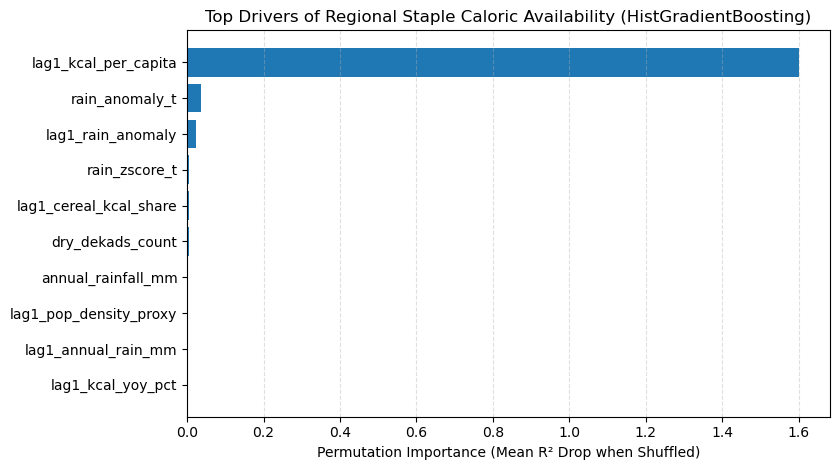

Updated model bundle with ranked permutation drivers:


,Feature,Importance_R2_Drop,Std
0,lag1_kcal_per_capita,1.6023,0.1342
1,rain_anomaly_t,0.0365,0.0054
2,lag1_rain_anomaly,0.0229,0.0031
3,rain_zscore_t,0.0055,0.0008
4,lag1_cereal_kcal_share,0.0052,0.0006
5,dry_dekads_count,0.0051,0.0006
6,annual_rainfall_mm,0.0024,0.0003
7,lag1_pop_density_proxy,0.0020,0.0003
8,lag1_annual_rain_mm,0.0012,0.0002
9,lag1_kcal_yoy_pct,0.0006,0.0001


In [63]:
"""
Compute Permutation Feature Importance & Update `ghana_food_v2.joblib`
======================================================================
Replaces the zero-filled `.feature_importances_` fallback from
HistGradientBoosting with model-agnostic permutation importance and stores
the ranked driver table inside `models/ghana_food_v2.joblib` for Streamlit.
"""

from sklearn.inspection import permutation_importance

bundle_path = Path("models/ghana_food_v2.joblib")
bundle = joblib.load(bundle_path)

final_reg = bundle["regressor"]
FEATURE_COLS = bundle["feature_cols"]

df = (
    pd.read_parquet(PROCESSED_DIR / "ghana_model_features.parquet")
    .sort_values(["year", "region"])
    .reset_index(drop=True)
)
X = df[FEATURE_COLS].copy()
y_reg = df["staple_kcal_per_capita_day"].values

# Compute permutation importance (measured by drop in R2 when each feature is shuffled)
perm = permutation_importance(
    final_reg, X, y_reg, n_repeats=30, random_state=42, scoring="r2"
)

driver_df = (
    pd.DataFrame({
        "Feature": FEATURE_COLS,
        "Importance_R2_Drop": np.round(perm.importances_mean, 4),
        "Std": np.round(perm.importances_std, 4),
    })
    .sort_values("Importance_R2_Drop", ascending=False)
    .reset_index(drop=True)
)

# Save clean horizontal bar chart of top drivers for portfolio & Streamlit display
top_drivers = driver_df.head(10).iloc[::-1]
plt.figure(figsize=(8.5, 4.8))
plt.barh(top_drivers["Feature"], top_drivers["Importance_R2_Drop"], color="#1f77b4")
plt.xlabel("Permutation Importance (Mean R² Drop when Shuffled)")
plt.title(f"Top Drivers of Regional Staple Caloric Availability ({bundle['regressor_name']})")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("reports/figures/shap_caloric_drivers.png", dpi=180)
plt.show()

# Store driver table inside the serialized bundle
bundle["feature_importance"] = driver_df.to_dict(orient="records")
joblib.dump(bundle, bundle_path)

print("Updated model bundle with ranked permutation drivers:")
display(driver_df.head(10))

In [65]:
"""
Ghana Regional Food Security & Climate Stress Simulator (v2)
============================================================
Interactive Streamlit decision-support app powered by the expanding-window
HistGradientBoosting & Random Forest ensembles saved in `models/ghana_food_v2.joblib`.

Modules:
1. Regional Baseline & "What-If" Shock Simulator (KPI cards + historical trend)
2. National 10-Region Stress-Test Comparison (baseline vs. simulated shock)
3. Model Explainability & Expanding-Window Backtest Audit (2020–2024 OOF)
"""

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

# ---------------------------------------------------------------------------
# Page Configuration & Cached Artifact Loaders
# ---------------------------------------------------------------------------
st.set_page_config(
    page_title="Ghana Food Security Simulator v2",
    page_icon="🌾",
    layout="wide",
    initial_sidebar_state="expanded",
)

MODEL_PATH = Path("models/ghana_food_v2.joblib")
DATA_PATH = Path("data/processed/ghana_model_features.parquet")


@st.cache_resource
def load_model_bundle(path: Path) -> dict:
    """Loads the serialized regressor, classifier, feature list, and metadata."""
    return joblib.load(path)


@st.cache_data
def load_panel_data(path: Path) -> pd.DataFrame:
    """Loads the 2012–2024 leak-free regional modeling panel."""
    return pd.read_parquet(path).sort_values(["region", "year"]).reset_index(drop=True)


# Guardrail check so missing files display a clear setup hint rather than a traceback
if not MODEL_PATH.exists() or not DATA_PATH.exists():
    st.error(
        "Missing model or dataset artifacts. Confirm `models/ghana_food_v2.joblib` "
        "and `data/processed/ghana_model_features.parquet` exist in your project directory."
    )
    st.stop()

bundle = load_model_bundle(MODEL_PATH)
df = load_panel_data(DATA_PATH)

reg_model = bundle["regressor"]
cls_model = bundle["classifier"]
FEATURE_COLS = bundle["feature_cols"]
KCAL_THRESHOLD = float(bundle.get("caloric_threshold_kcal", 2100.0))

# Precompute regional historical rainfall mean & std for consistent z-score updates
region_rain_stats = (
    df.groupby("region")["annual_rainfall_mm"]
    .agg(mean_rain="mean", std_rain="std")
    .assign(std_rain=lambda d: d["std_rain"].replace(0, 1.0))
)


def apply_what_if_shocks(
    base_rows: pd.DataFrame,
    rain_anom_delta_pct: float,
    dry_dekad_delta: int,
    price_shock_pct: float,
    shannon_delta: float,
    cereal_share_delta: float,
) -> pd.DataFrame:
    """
    Applies user-selected climate, price, and cropping-system shocks to a copy
    of the baseline feature rows while keeping engineered cross-features consistent.
    """
    sim = base_rows.copy()

    # 1. Growing-season rainfall anomaly & proportional annual rainfall adjustment
    sim["rain_anomaly_t"] = (sim["rain_anomaly_t"] + rain_anom_delta_pct).clip(40.0, 160.0)
    rain_scale = (1.0 + rain_anom_delta_pct / 100.0).clip(0.50, 1.50)
    sim["annual_rainfall_mm"] = sim["annual_rainfall_mm"] * rain_scale

    # Recompute regional rainfall z-score and 2-year compound drought index
    means = sim["region"].map(region_rain_stats["mean_rain"])
    stds = sim["region"].map(region_rain_stats["std_rain"])
    sim["rain_zscore_t"] = (sim["annual_rainfall_mm"] - means) / stds
    sim["compound_2yr_rain_anom"] = 0.6 * sim["rain_anomaly_t"] + 0.4 * sim["lag1_rain_anomaly"]

    # 2. Dry dekads (10-day dry spells during the cropping season)
    sim["dry_dekads_count"] = (sim["dry_dekads_count"] + dry_dekad_delta).clip(0, 24)

    # 3. Rural wholesale staple price shock
    price_mult = (1.0 + price_shock_pct / 100.0).clip(0.50, 2.50)
    sim["lag1_wholesale_price_ghs"] = sim["lag1_wholesale_price_ghs"] * price_mult
    sim["lag1_price_yoy_pct"] = sim["lag1_price_yoy_pct"] + price_shock_pct

    # 4. Agro-ecological resilience levers: crop diversification & cereal vs. root mix
    sim["lag1_crop_shannon_idx"] = (sim["lag1_crop_shannon_idx"] + shannon_delta).clip(0.0, 2.1)
    sim["lag1_cereal_kcal_share"] = (sim["lag1_cereal_kcal_share"] + cereal_share_delta).clip(0.05, 0.95)

    return sim


# ---------------------------------------------------------------------------
# Sidebar: Scenario & "What-If" Policy Controls
# ---------------------------------------------------------------------------
st.sidebar.header("🎛️ Scenario & Policy Controls")

regions_sorted = sorted(df["region"].unique().tolist())
years_sorted = sorted(df["year"].unique().tolist(), reverse=True)

selected_region = st.sidebar.selectbox("Target Legacy Region", regions_sorted, index=0)
selected_year = st.sidebar.selectbox("Reference Baseline Year", years_sorted, index=0)

st.sidebar.markdown("---")
st.sidebar.subheader("Climate & Market Shocks")

rain_anom_delta = st.sidebar.slider(
    "Growing-Season Rainfall Anomaly Shift (% pts)",
    min_value=-40,
    max_value=30,
    value=0,
    step=5,
    help="Negative values simulate drought stress; positive values simulate wetter seasons.",
)

dry_dekad_delta = st.sidebar.slider(
    "Additional Dry Dekads (10-day dry spells)",
    min_value=-4,
    max_value=8,
    value=0,
    step=1,
)

price_shock_pct = st.sidebar.slider(
    "Wholesale Staple Price Shock (%)",
    min_value=-20,
    max_value=60,
    value=0,
    step=5,
)

st.sidebar.markdown("---")
st.sidebar.subheader("Agro-Ecological Resilience Levers")

shannon_delta = st.sidebar.slider(
    "Crop Diversity Shift (Shannon Index)",
    min_value=-0.40,
    max_value=0.40,
    value=0.00,
    step=0.05,
    help="Higher Shannon Index reflects broader multi-crop diversification.",
)

cereal_share_delta = st.sidebar.slider(
    "Cereal vs. Root/Tuber Share Shift",
    min_value=-0.20,
    max_value=0.20,
    value=0.00,
    step=0.05,
)

# ---------------------------------------------------------------------------
# Header & Baseline vs. Simulated Inference
# ---------------------------------------------------------------------------
st.title("🌾 Ghana Regional Food Security & Climate Stress Simulator (v2)")
st.caption(
    f"Regressor: **{bundle['regressor_name']}** | "
    f"Deficit Classifier: **{bundle['classifier_name']}** | "
    f"FAO/WFP Caloric Threshold: **{KCAL_THRESHOLD:,.0f} kcal/person/day**"
)

# Extract baseline row for the selected region & year, plus all 10 regions in that year
year_slice = df[df["year"] == selected_year].copy().reset_index(drop=True)
sim_year_slice = apply_what_if_shocks(
    year_slice,
    rain_anom_delta,
    dry_dekad_delta,
    price_shock_pct,
    shannon_delta,
    cereal_share_delta,
)

year_slice["pred_kcal_base"] = reg_model.predict(year_slice[FEATURE_COLS])
year_slice["risk_prob_base"] = cls_model.predict_proba(year_slice[FEATURE_COLS])[:, 1]

sim_year_slice["pred_kcal_sim"] = reg_model.predict(sim_year_slice[FEATURE_COLS])
sim_year_slice["risk_prob_sim"] = cls_model.predict_proba(sim_year_slice[FEATURE_COLS])[:, 1]

reg_base = year_slice[year_slice["region"] == selected_region].iloc[0]
reg_sim = sim_year_slice[sim_year_slice["region"] == selected_region].iloc[0]

# Top-level KPI Metrics
k1, k2, k3, k4 = st.columns(4)
kcal_diff = reg_sim["pred_kcal_sim"] - reg_base["pred_kcal_base"]
prob_diff = (reg_sim["risk_prob_sim"] - reg_base["risk_prob_base"]) * 100.0

k1.metric(
    label=f"{selected_region} Observed ({selected_year})",
    value=f"{reg_base['staple_kcal_per_capita_day']:,.0f} kcal/day",
    delta=f"{reg_base['staple_kcal_per_capita_day'] - KCAL_THRESHOLD:+,.0f} vs threshold",
)
k2.metric(
    label="Model Baseline Prediction",
    value=f"{reg_base['pred_kcal_base']:,.0f} kcal/day",
    delta=f"Deficit Risk: {reg_base['risk_prob_base']*100:.1f}%",
    delta_color="off",
)
k3.metric(
    label="Simulated Scenario Output",
    value=f"{reg_sim['pred_kcal_sim']:,.0f} kcal/day",
    delta=f"{kcal_diff:+,.0f} kcal vs baseline",
)
k4.metric(
    label="Simulated Deficit Probability",
    value=f"{reg_sim['risk_prob_sim']*100:.1f}%",
    delta=f"{prob_diff:+.1f} percentage pts",
    delta_color="inverse",
)

# ---------------------------------------------------------------------------
# Main Dashboard Tabs
# ---------------------------------------------------------------------------
tab_sim, tab_nat, tab_audit = st.tabs(
    [
        "📈 Regional Trajectory & What-If",
        "🗺️ 10-Region National Stress Test",
        "🔍 Model Explainability & Backtest",
    ]
)

# --- TAB 1: Regional Trajectory & What-If Comparison ---
with tab_sim:
    reg_hist = df[df["region"] == selected_region].sort_values("year")

    fig_hist = go.Figure()
    fig_hist.add_trace(
        go.Scatter(
            x=reg_hist["year"],
            y=reg_hist["staple_kcal_per_capita_day"],
            mode="lines+markers",
            name="Observed Staple Supply (kcal/day)",
            line=dict(color="#1f77b4", width=3),
        )
    )
    # Highlight simulated point in the selected reference year
    fig_hist.add_trace(
        go.Scatter(
            x=[selected_year],
            y=[reg_sim["pred_kcal_sim"]],
            mode="markers",
            name="Simulated What-If Scenario",
            marker=dict(color="#d62728", size=14, symbol="diamond"),
        )
    )
    fig_hist.add_hline(
        y=KCAL_THRESHOLD,
        line_dash="dash",
        line_color="#ff7f0e",
        annotation_text=f"FAO/WFP Threshold ({KCAL_THRESHOLD:,.0f} kcal/day)",
    )
    fig_hist.update_layout(
        title=f"{selected_region}: Historical Caloric Supply vs. Simulated Scenario ({selected_year})",
        xaxis_title="Year",
        yaxis_title="Staple Availability (kcal / person / day)",
        height=420,
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    )
    st.plotly_chart(fig_hist, width="stretch")

    # Side-by-side feature inspection table for transparency
    with st.expander("Inspect Baseline vs. Shocked Feature Vector"):
        comp_df = pd.DataFrame(
            {
                "Feature": FEATURE_COLS,
                "Baseline Value": [round(float(reg_base[c]), 3) for c in FEATURE_COLS],
                "Simulated Value": [round(float(reg_sim[c]), 3) for c in FEATURE_COLS],
            }
        )
        st.dataframe(comp_df, hide_index=True, width="stretch")

# --- TAB 2: All-10-Regions National Stress Test ---
with tab_nat:
    nat_comp = pd.DataFrame(
        {
            "Region": year_slice["region"],
            "Observed_kcal": year_slice["staple_kcal_per_capita_day"].round(0),
            "Baseline_Pred_kcal": year_slice["pred_kcal_base"].round(0),
            "Simulated_kcal": sim_year_slice["pred_kcal_sim"].round(0),
            "Delta_kcal": (sim_year_slice["pred_kcal_sim"] - year_slice["pred_kcal_base"]).round(0),
            "Simulated_Risk_Prob": (sim_year_slice["risk_prob_sim"] * 100).round(1),
            "Status": np.where(
                sim_year_slice["pred_kcal_sim"] < KCAL_THRESHOLD,
                "⚠️ Deficit Risk (<2,100)",
                "✅ Adequate Supply",
            ),
        }
    ).sort_values("Simulated_kcal")

    fig_bar = px.bar(
        nat_comp,
        x="Simulated_kcal",
        y="Region",
        color="Status",
        orientation="h",
        color_discrete_map={
            "⚠️ Deficit Risk (<2,100)": "#d62728",
            "✅ Adequate Supply": "#2ca02c",
        },
        title=f"Simulated Daily Staple Calories Across All 10 Legacy Regions ({selected_year})",
        labels={"Simulated_kcal": "Predicted Supply (kcal/person/day)"},
        height=440,
    )
    fig_bar.add_vline(x=KCAL_THRESHOLD, line_dash="dash", line_color="#ff7f0e")
    st.plotly_chart(fig_bar, width="stretch")

    st.dataframe(nat_comp, hide_index=True, width="stretch")

# --- TAB 3: Model Explainability & Backtest Audit ---
with tab_audit:
    c_left, c_right = st.columns([1.2, 1.0])

    with c_left:
        st.subheader("Top Model Drivers (Permutation R² Drop)")
        imp_records = bundle.get("feature_importance", [])
        if imp_records:
            imp_df = pd.DataFrame(imp_records).head(10).iloc[::-1]
            fig_imp = px.bar(
                imp_df,
                x="Importance_R2_Drop",
                y="Feature",
                orientation="h",
                title=f"Feature Importance ({bundle['regressor_name']})",
                labels={"Importance_R2_Drop": "Mean R² Drop When Shuffled"},
                height=390,
            )
            st.plotly_chart(fig_imp, width="stretch")
        else:
            st.info("Run the Week 2 permutation importance patch to populate driver rankings.")

    with c_right:
        st.subheader("Expanding-Window Backtest (2020–2024)")
        st.markdown("**Regression Out-of-Sample Metrics (`staple_kcal_per_capita_day`)**")
        st.dataframe(pd.DataFrame(bundle["regression_metrics"]), hide_index=True, width="stretch")

        st.markdown("**Classification Out-of-Sample Metrics (`deficit_risk_flag`)**")
        st.dataframe(pd.DataFrame(bundle["classification_metrics"]), hide_index=True, width="stretch")

2026-11-26 04:34:51.113 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-26 04:34:51.533 
  command:

    streamlit run C:\Users\user\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-26 04:34:51.694 No runtime found, using MemoryCacheStorageManager
2026-11-26 04:34:51.725 Session state does not function when running a script without `streamlit run`


AttributeError: 'float' object has no attribute 'clip'

In [67]:
%%writefile app.py
"""
Ghana Regional Food Security & Climate Stress Simulator (v2)
============================================================
Interactive Streamlit decision-support app powered by the expanding-window
HistGradientBoosting & Random Forest ensembles saved in `models/ghana_food_v2.joblib`.
"""

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

# ---------------------------------------------------------------------------
# Page Configuration & Cached Artifact Loaders
# ---------------------------------------------------------------------------
st.set_page_config(
    page_title="Ghana Food Security Simulator v2",
    page_icon="🌾",
    layout="wide",
    initial_sidebar_state="expanded",
)

MODEL_PATH = Path("models/ghana_food_v2.joblib")
DATA_PATH = Path("data/processed/ghana_model_features.parquet")


@st.cache_resource
def load_model_bundle(path: Path) -> dict:
    """Loads the serialized regressor, classifier, feature list, and metadata."""
    return joblib.load(path)


@st.cache_data
def load_panel_data(path: Path) -> pd.DataFrame:
    """Loads the 2012–2024 leak-free regional modeling panel."""
    return pd.read_parquet(path).sort_values(["region", "year"]).reset_index(drop=True)


if not MODEL_PATH.exists() or not DATA_PATH.exists():
    st.error(
        "Missing model or dataset artifacts. Confirm `models/ghana_food_v2.joblib` "
        "and `data/processed/ghana_model_features.parquet` exist in your project directory."
    )
    st.stop()

bundle = load_model_bundle(MODEL_PATH)
df = load_panel_data(DATA_PATH)

reg_model = bundle["regressor"]
cls_model = bundle["classifier"]
FEATURE_COLS = bundle["feature_cols"]
KCAL_THRESHOLD = float(bundle.get("caloric_threshold_kcal", 2100.0))

# Precompute regional historical rainfall mean & std for consistent z-score updates
region_rain_stats = (
    df.groupby("region")["annual_rainfall_mm"]
    .agg(mean_rain="mean", std_rain="std")
    .assign(std_rain=lambda d: d["std_rain"].replace(0, 1.0))
)


def apply_what_if_shocks(
    base_rows: pd.DataFrame,
    rain_anom_delta_pct: float,
    dry_dekad_delta: int,
    price_shock_pct: float,
    shannon_delta: float,
    cereal_share_delta: float,
) -> pd.DataFrame:
    """
    Applies user-selected climate, price, and cropping-system shocks to a copy
    of the baseline feature rows while keeping engineered cross-features consistent.
    """
    sim = base_rows.copy()

    # 1. Growing-season rainfall anomaly & proportional annual rainfall adjustment
    sim["rain_anomaly_t"] = (sim["rain_anomaly_t"] + rain_anom_delta_pct).clip(40.0, 160.0)
    rain_scale = float(np.clip(1.0 + rain_anom_delta_pct / 100.0, 0.50, 1.50))
    sim["annual_rainfall_mm"] = sim["annual_rainfall_mm"] * rain_scale

    # Recompute regional rainfall z-score and 2-year compound drought index
    means = sim["region"].map(region_rain_stats["mean_rain"])
    stds = sim["region"].map(region_rain_stats["std_rain"])
    sim["rain_zscore_t"] = (sim["annual_rainfall_mm"] - means) / stds
    sim["compound_2yr_rain_anom"] = 0.6 * sim["rain_anomaly_t"] + 0.4 * sim["lag1_rain_anomaly"]

    # 2. Dry dekads (10-day dry spells during the cropping season)
    sim["dry_dekads_count"] = (sim["dry_dekads_count"] + dry_dekad_delta).clip(0, 24)

    # 3. Rural wholesale staple price shock
    price_mult = float(np.clip(1.0 + price_shock_pct / 100.0, 0.50, 2.50))
    sim["lag1_wholesale_price_ghs"] = sim["lag1_wholesale_price_ghs"] * price_mult
    sim["lag1_price_yoy_pct"] = sim["lag1_price_yoy_pct"] + price_shock_pct

    # 4. Agro-ecological resilience levers: crop diversification & cereal vs. root mix
    sim["lag1_crop_shannon_idx"] = (sim["lag1_crop_shannon_idx"] + shannon_delta).clip(0.0, 2.1)
    sim["lag1_cereal_kcal_share"] = (sim["lag1_cereal_kcal_share"] + cereal_share_delta).clip(0.05, 0.95)

    return sim


# ---------------------------------------------------------------------------
# Sidebar: Scenario & "What-If" Policy Controls
# ---------------------------------------------------------------------------
st.sidebar.header("🎛️ Scenario & Policy Controls")

regions_sorted = sorted(df["region"].unique().tolist())
years_sorted = sorted(df["year"].unique().tolist(), reverse=True)

selected_region = st.sidebar.selectbox("Target Legacy Region", regions_sorted, index=0)
selected_year = st.sidebar.selectbox("Reference Baseline Year", years_sorted, index=0)

st.sidebar.markdown("---")
st.sidebar.subheader("Climate & Market Shocks")

rain_anom_delta = st.sidebar.slider(
    "Growing-Season Rainfall Anomaly Shift (% pts)",
    min_value=-40,
    max_value=30,
    value=0,
    step=5,
    help="Negative values simulate drought stress; positive values simulate wetter seasons.",
)

dry_dekad_delta = st.sidebar.slider(
    "Additional Dry Dekads (10-day dry spells)",
    min_value=-4,
    max_value=8,
    value=0,
    step=1,
)

price_shock_pct = st.sidebar.slider(
    "Wholesale Staple Price Shock (%)",
    min_value=-20,
    max_value=60,
    value=0,
    step=5,
)

st.sidebar.markdown("---")
st.sidebar.subheader("Agro-Ecological Resilience Levers")

shannon_delta = st.sidebar.slider(
    "Crop Diversity Shift (Shannon Index)",
    min_value=-0.40,
    max_value=0.40,
    value=0.00,
    step=0.05,
    help="Higher Shannon Index reflects broader multi-crop diversification.",
)

cereal_share_delta = st.sidebar.slider(
    "Cereal vs. Root/Tuber Share Shift",
    min_value=-0.20,
    max_value=0.20,
    value=0.00,
    step=0.05,
)

# ---------------------------------------------------------------------------
# Header & Baseline vs. Simulated Inference
# ---------------------------------------------------------------------------
st.title("🌾 Ghana Regional Food Security & Climate Stress Simulator (v2)")
st.caption(
    f"Regressor: **{bundle['regressor_name']}** | "
    f"Deficit Classifier: **{bundle['classifier_name']}** | "
    f"FAO/WFP Caloric Threshold: **{KCAL_THRESHOLD:,.0f} kcal/person/day**"
)

year_slice = df[df["year"] == selected_year].copy().reset_index(drop=True)
sim_year_slice = apply_what_if_shocks(
    year_slice,
    rain_anom_delta,
    dry_dekad_delta,
    price_shock_pct,
    shannon_delta,
    cereal_share_delta,
)

year_slice["pred_kcal_base"] = reg_model.predict(year_slice[FEATURE_COLS])
year_slice["risk_prob_base"] = cls_model.predict_proba(year_slice[FEATURE_COLS])[:, 1]

sim_year_slice["pred_kcal_sim"] = reg_model.predict(sim_year_slice[FEATURE_COLS])
sim_year_slice["risk_prob_sim"] = cls_model.predict_proba(sim_year_slice[FEATURE_COLS])[:, 1]

reg_base = year_slice[year_slice["region"] == selected_region].iloc[0]
reg_sim = sim_year_slice[sim_year_slice["region"] == selected_region].iloc[0]

# Top-level KPI Metrics
k1, k2, k3, k4 = st.columns(4)
kcal_diff = reg_sim["pred_kcal_sim"] - reg_base["pred_kcal_base"]
prob_diff = (reg_sim["risk_prob_sim"] - reg_base["risk_prob_base"]) * 100.0

k1.metric(
    label=f"{selected_region} Observed ({selected_year})",
    value=f"{reg_base['staple_kcal_per_capita_day']:,.0f} kcal/day",
    delta=f"{reg_base['staple_kcal_per_capita_day'] - KCAL_THRESHOLD:+,.0f} vs threshold",
)
k2.metric(
    label="Model Baseline Prediction",
    value=f"{reg_base['pred_kcal_base']:,.0f} kcal/day",
    delta=f"Deficit Risk: {reg_base['risk_prob_base']*100:.1f}%",
    delta_color="off",
)
k3.metric(
    label="Simulated Scenario Output",
    value=f"{reg_sim['pred_kcal_sim']:,.0f} kcal/day",
    delta=f"{kcal_diff:+,.0f} kcal vs baseline",
)
k4.metric(
    label="Simulated Deficit Probability",
    value=f"{reg_sim['risk_prob_sim']*100:.1f}%",
    delta=f"{prob_diff:+.1f} percentage pts",
    delta_color="inverse",
)

# ---------------------------------------------------------------------------
# Main Dashboard Tabs
# ---------------------------------------------------------------------------
tab_sim, tab_nat, tab_audit = st.tabs(
    [
        "📈 Regional Trajectory & What-If",
        "🗺️ 10-Region National Stress Test",
        "🔍 Model Explainability & Backtest",
    ]
)

with tab_sim:
    reg_hist = df[df["region"] == selected_region].sort_values("year")

    fig_hist = go.Figure()
    fig_hist.add_trace(
        go.Scatter(
            x=reg_hist["year"],
            y=reg_hist["staple_kcal_per_capita_day"],
            mode="lines+markers",
            name="Observed Staple Supply (kcal/day)",
            line=dict(color="#1f77b4", width=3),
        )
    )
    fig_hist.add_trace(
        go.Scatter(
            x=[selected_year],
            y=[reg_sim["pred_kcal_sim"]],
            mode="markers",
            name="Simulated What-If Scenario",
            marker=dict(color="#d62728", size=14, symbol="diamond"),
        )
    )
    fig_hist.add_hline(
        y=KCAL_THRESHOLD,
        line_dash="dash",
        line_color="#ff7f0e",
        annotation_text=f"FAO/WFP Threshold ({KCAL_THRESHOLD:,.0f} kcal/day)",
    )
    fig_hist.update_layout(
        title=f"{selected_region}: Historical Caloric Supply vs. Simulated Scenario ({selected_year})",
        xaxis_title="Year",
        yaxis_title="Staple Availability (kcal / person / day)",
        height=420,
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    )
    st.plotly_chart(fig_hist, width="stretch")

    with st.expander("Inspect Baseline vs. Shocked Feature Vector"):
        comp_df = pd.DataFrame(
            {
                "Feature": FEATURE_COLS,
                "Baseline Value": [round(float(reg_base[c]), 3) for c in FEATURE_COLS],
                "Simulated Value": [round(float(reg_sim[c]), 3) for c in FEATURE_COLS],
            }
        )
        st.dataframe(comp_df, hide_index=True, width="stretch")

with tab_nat:
    nat_comp = pd.DataFrame(
        {
            "Region": year_slice["region"],
            "Observed_kcal": year_slice["staple_kcal_per_capita_day"].round(0),
            "Baseline_Pred_kcal": year_slice["pred_kcal_base"].round(0),
            "Simulated_kcal": sim_year_slice["pred_kcal_sim"].round(0),
            "Delta_kcal": (sim_year_slice["pred_kcal_sim"] - year_slice["pred_kcal_base"]).round(0),
            "Simulated_Risk_Prob": (sim_year_slice["risk_prob_sim"] * 100).round(1),
            "Status": np.where(
                sim_year_slice["pred_kcal_sim"] < KCAL_THRESHOLD,
                "⚠️ Deficit Risk (<2,100)",
                "✅ Adequate Supply",
            ),
        }
    ).sort_values("Simulated_kcal")

    fig_bar = px.bar(
        nat_comp,
        x="Simulated_kcal",
        y="Region",
        color="Status",
        orientation="h",
        color_discrete_map={
            "⚠️ Deficit Risk (<2,100)": "#d62728",
            "✅ Adequate Supply": "#2ca02c",
        },
        title=f"Simulated Daily Staple Calories Across All 10 Legacy Regions ({selected_year})",
        labels={"Simulated_kcal": "Predicted Supply (kcal/person/day)"},
        height=440,
    )
    fig_bar.add_vline(x=KCAL_THRESHOLD, line_dash="dash", line_color="#ff7f0e")
    st.plotly_chart(fig_bar, width="stretch")

    st.dataframe(nat_comp, hide_index=True, width="stretch")

with tab_audit:
    c_left, c_right = st.columns([1.2, 1.0])

    with c_left:
        st.subheader("Top Model Drivers (Permutation R² Drop)")
        imp_records = bundle.get("feature_importance", [])
        if imp_records:
            imp_df = pd.DataFrame(imp_records).head(10).iloc[::-1]
            fig_imp = px.bar(
                imp_df,
                x="Importance_R2_Drop",
                y="Feature",
                orientation="h",
                title=f"Feature Importance ({bundle['regressor_name']})",
                labels={"Importance_R2_Drop": "Mean R² Drop When Shuffled"},
                height=390,
            )
            st.plotly_chart(fig_imp, width="stretch")
        else:
            st.info("Run the Week 2 permutation importance patch to populate driver rankings.")

    with c_right:
        st.subheader("Expanding-Window Backtest (2020–2024)")
        st.markdown("**Regression Out-of-Sample Metrics (`staple_kcal_per_capita_day`)**")
        st.dataframe(pd.DataFrame(bundle["regression_metrics"]), hide_index=True, width="stretch")

        st.markdown("**Classification Out-of-Sample Metrics (`deficit_risk_flag`)**")
        st.dataframe(pd.DataFrame(bundle["classification_metrics"]), hide_index=True, width="stretch")

Writing app.py


In [73]:
import subprocess
import time
import webbrowser

# Start Streamlit in headless background mode so it does not block your notebook kernel
proc = subprocess.Popen(["streamlit", "run", "app.py", "--server.headless", "true"])
time.sleep(3)
webbrowser.open("http://localhost:8501")
print(f"Streamlit server running at http://localhost:8501 (PID: {proc.pid})")

Streamlit server running at http://localhost:8501 (PID: 11020)


In [71]:
from pathlib import Path

app_path = Path("app.py")
code = app_path.read_text(encoding="utf-8")
app_path.write_text(code.replace('width="stretch"', "use_container_width=True"), encoding="utf-8")
print("Patched app.py: replaced width='stretch' with use_container_width=True")

Patched app.py: replaced width='stretch' with use_container_width=True


In [79]:
from pathlib import Path

# 1. Create requirements.txt
requirements_lines = [
    "streamlit>=1.36.0",
    "pandas>=2.1.0",
    "numpy>=1.26.0",
    "scikit-learn>=1.4.0",
    "joblib>=1.3.0",
    "plotly>=5.18.0",
    "pyarrow>=14.0.0",
    "pdfplumber>=0.10.0",
    "matplotlib>=3.8.0",
]
Path("requirements.txt").write_text("\n".join(requirements_lines) + "\n", encoding="utf-8")

# 2. Create .gitignore
gitignore_lines = [
    "# Python & Jupyter artifacts",
    "__pycache__/",
    "*.py[cod]",
    ".ipynb_checkpoints/",
    ".venv/",
    "venv/",
    "env/",
    "",
    "# OS & editor files",
    ".DS_Store",
    "Thumbs.db",
    ".vscode/",
    "",
    "# Raw PDFs (keep processed Parquet and model artifacts tracked for Streamlit)",
    "data/raw/*.pdf",
]
Path(".gitignore").write_text("\n".join(gitignore_lines) + "\n", encoding="utf-8")

# 3. Create README.md using a single-line list (immune to Jupyter multiline paste issues)
readme_lines = [
    "# Ghana Regional Food Security & Climate Stress Simulator (v2)",
    "",
    "An end-to-end spatial-temporal machine learning pipeline and interactive Streamlit decision-support simulator forecasting **regional staple caloric availability (`kcal/person/day`)** and **caloric deficit risk (`< 2,100 kcal/day` FAO/WFP threshold)** across Ghana's 10 legacy administrative regions (`2012-2024`).",
    "",
    "---",
    "",
    "## Project Architecture & Data Pipeline",
    "",
    "1. **Subnational Climate & Macro Ingestion:**",
    "   - Harmonizes subnational CHIRPS rainfall metrics (`annual_rainfall_mm`, `growing_season_anomaly_pct`, `dry_dekads_count`) across Ghana's 10 legacy administrative regions (`GH02`-`GH15`), rolling up post-2019 regional splits (`Ahafo`, `Bono`, `Bono East`, `North East`, `Savannah`, `Oti`, `Western North`) back to consistent legacy boundaries.",
    "   - Integrates World Bank macroeconomic & demographic series and MoFA SRID *Facts & Figures* (`2019` & `2024` editions) national crop production (`2010-2024`), regional crop shares, and rural wholesale staple prices.",
    "",
    "2. **Leak-Free Temporal Feature Engineering (`data/processed/ghana_model_features.parquet`):**",
    "   - **Lagged Supply Momentum:** `lag1_kcal_per_capita`, `lag1_kcal_yoy_pct`, `lag1_pop_density_proxy`.",
    "   - **Compound Climate Shocks:** `rain_anomaly_t`, `lag1_rain_anomaly`, `compound_2yr_rain_anom` (`0.6 * anom_t + 0.4 * anom_{t-1}`), `rain_zscore_t`, and `dry_dekads_count`.",
    "   - **Agro-Ecological Resilience & Market Stress:** Lagged crop portfolio Shannon Diversity Index (`lag1_crop_shannon_idx`), cereal vs. root/tuber caloric share (`lag1_cereal_kcal_share`), and rural wholesale price shocks (`lag1_wholesale_price_ghs`, `lag1_price_yoy_pct`).",
    "",
    "3. **Panel-Aware Expanding-Window Validation (`2020-2024` Holdout):**",
    "   - Evaluates models strictly forward in time (`Train <= t-1` -> `Test year t`, keeping all 10 regions of each test year together to prevent cross-region macro leakage).",
    "",
    "| Task | Selected Model | Out-of-Sample Metric (2020-2024) |",
    "| :--- | :--- | :--- |",
    "| **Caloric Supply Regression** (`staple_kcal_per_capita_day`) | `HistGradientBoostingRegressor` | **$R^2 = 0.900$** \\| MAE = `719.5 kcal/day` \\| RMSE = `977.1 kcal/day` |",
    "| **Deficit Risk Classification** (`< 2,100 kcal/day`) | `RandomForestClassifier` (balanced) | **ROC-AUC = `1.000`** \\| **PR-AUC = `1.000`** \\| **F1 = `1.000`** |",
    "",
    "*(Note: Modeled caloric estimates reflect regional domestic staple production converted via FAO/WFP energy densities after an assumed 85% net edible/post-harvest availability factor, prior to inter-regional trade and commercial imports.)*",
    "",
    "---",
    "",
    "## Interactive Streamlit Dashboard (`app.py`)",
    "",
    "- **Scenario & Policy Controls:** Adjust growing-season rainfall anomalies (`-40%` to `+30%`), dry dekads (`-4` to `+8`), wholesale staple price shocks (`-20%` to `+60%`), and cropping-system diversification levers (`Shannon Index`, cereal share).",
    "- **Regional Trajectory & What-If:** Compares observed historical caloric trajectories (`2012-2024`) against simulated shock outcomes and exposes the baseline vs. shocked feature vector.",
    "- **10-Region National Stress Test:** Applies active climate/price shocks across all 10 regions simultaneously to identify regions tipping below the `2,100 kcal/person/day` threshold.",
    "- **Model Explainability & Backtest Audit:** Displays permutation importance rankings (`R^2` drop) and out-of-sample backtest scorecards.",
    "",
    "---",
    "",
    "## Quickstart",
    "",
    "```bash",
    "# 1. Install dependencies",
    "pip install -r requirements.txt",
    "",
    "# 2. Launch the interactive simulator",
    "streamlit run app.py",
    "```",
    "",
    "## Repository Structure",
    "",
    "```text",
    "v2/",
    "├── app.py                                      # Interactive Streamlit dashboard",
    "├── requirements.txt                            # Python dependencies",
    "├── README.md                                   # Project documentation & validation summary",
    "├── models/",
    "│   └── ghana_food_v2.joblib                    # Serialized regressor, classifier & metadata",
    "├── data/",
    "│   └── processed/",
    "│       ├── ghana_subnat_rainfall.parquet       # Harmonized 10-region CHIRPS rainfall",
    "│       ├── ghana_wb_macro.parquet              # World Bank macro indicators",
    "│       ├── ghana_food_panel.parquet            # Master 10-region x 15-year panel",
    "│       └── ghana_model_features.parquet        # Leak-free modeling feature matrix",
    "└── reports/",
    "    └── figures/",
    "        └── shap_caloric_drivers.png            # Permutation feature importance plot",
    "```",
]

Path("README.md").write_text("\n".join(readme_lines) + "\n", encoding="utf-8")
print("Created requirements.txt, .gitignore, and README.md in:", Path.cwd())

Created requirements.txt, .gitignore, and README.md in: C:\Users\user\data-science-portfolio\ghana-food-security-analysis\v2
